# FP-Growth: Khai thác tập phổ biến (Group 23)

Notebook demo: chạy lại toàn bộ thực nghiệm và hai ứng dụng bằng cài đặt FP-Growth của nhóm
(Han, Pei, Yin, Mao 2004). Chạy được trên Google Colab và ở máy: **Runtime → Run all**.

| Phần | Nội dung |
|---|---|
| 0 | Cài đặt môi trường |
| 1 | Chương 1: Demo FP-Growth: dòng lệnh SPMF, bản cơ bản vs tối ưu, unit test |
| 2 | Chương 2: correctness so với SPMF, thời gian, bộ nhớ, scalability, độ dài giao dịch |
| 3 | Ứng dụng 1: phân tích giỏ hàng và luật kết hợp (Groceries, Retail) |
| 4 | Ứng dụng 2: khai thác mẫu trong chuỗi DNA (splice junction) |

# 0. Cài đặt môi trường

In [1]:
import os, sys

REPO_URL = "https://github.com/KhoaTranFitus/Frequent_Itemset.git"
REPO_DIR = "/content/Frequent_Itemset"

if "google.colab" in sys.modules:
    if not os.path.exists(REPO_DIR):
        !git clone -q {REPO_URL} {REPO_DIR}      # lần đầu: tải repo về
    else:
        !git -C {REPO_DIR} pull -q               # đã có: cập nhật bản mới nhất
    os.chdir(REPO_DIR)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")                               # chạy ở máy, notebook nằm trong notebooks/

sys.path.insert(0, os.getcwd())                  # để import được src/ và scripts/
!pip install -q -r requirements.txt
print("Thư mục làm việc:", os.getcwd())

Thư mục làm việc: d:\datamining\Group_23


## 1. Chương 1: Demo FP-Growth 

Cài đặt chính: `src/algorithm/fpgrowth.py` (FP-Growth + tối ưu single path, Lemma 3.2);
bản cơ bản không tối ưu: `src/algorithm/fpgrowth_basic.py`. Phần này kiểm tra ba yêu cầu
của Chương 1: **I/O chuẩn SPMF và tham số dòng lệnh**, **kết quả đúng**, **unit test**.



### 1.1. Chạy bằng dòng lệnh, định dạng SPMF

Input: mỗi dòng một giao dịch, item là số nguyên. Output: mỗi dòng một itemset kèm `#SUP:`
(support tuyệt đối). `--minsup` là ngưỡng tương đối, đổi sang tuyệt đối bằng
`min_count = ceil(minsup × số giao dịch)`.

In [2]:
!{sys.executable} -m src.algorithm.fpgrowth data/toy/toy_test1.txt --minsup 0.6 --output out.txt
print(open("out.txt", encoding="utf-8").read())

5 giao dịch, min_count = 3, tìm được 18 tập phổ biến
1 #SUP: 3
1 3 #SUP: 3
1 6 #SUP: 3
1 3 6 #SUP: 3
2 #SUP: 3
13 #SUP: 3
1 13 #SUP: 3
3 13 #SUP: 3
6 13 #SUP: 3
1 3 13 #SUP: 3
1 6 13 #SUP: 3
3 6 13 #SUP: 3
1 3 6 13 #SUP: 3
16 #SUP: 3
3 16 #SUP: 3
3 #SUP: 4
6 #SUP: 4
3 6 #SUP: 3



CSDL có 5 giao dịch, minsup 0,6 nên `min_count = ceil(0,6 × 5) = 3`: chỉ giữ itemset xuất
hiện trong ít nhất 3 giao dịch. Kết quả 18 itemset, đúng định dạng SPMF.



### 1.2. Bản cơ bản và bản tối ưu trên các CSDL nhỏ

Cột `tay` là số itemset **đếm tay**; `basic==opt` kiểm tra hai bản cho kết quả giống hệt
nhau (cùng itemset, cùng support). Cột `opt==SPMF` ghi `no ref` khi máy chưa có file tham
chiếu của SPMF (ví dụ trên Colab).

In [3]:
!{sys.executable} -m scripts.run_toy_compare

test    minsup  tay  basic   opt  basic==opt  opt==SPMF  t_basic(ms)  t_opt(ms)
test1      0.6   18     18    18        True       100%        0.184      0.119
test2      0.5   10     10    10        True       100%        0.109      0.110
test2    0.375   14     14    14        True       100%        0.133      0.125
test3      0.5   15     15    15        True       100%        0.105      0.051
test3     0.33   31     31    31        True       100%        0.220      0.076
test4      0.3    6      6     6        True       100%        0.067      0.069
test4      0.2   13     13    13        True       100%        0.115      0.105


### 1.3. Unit test

Các test dưới đây chạy khoảng 1 giây, gồm cả **7 test so với SPMF** trên các CSDL toy (file
tham chiếu của SPMF cho 7 ca này có sẵn trong `data/output/ref/`). Kết quả mong đợi:
**70 passed**. Bộ test đầy đủ kể cả benchmark (khoảng 7 phút, cần sinh thêm ref benchmark
bằng `python -m scripts.make_refs --group benchmark`): **98 passed**, ghi trong README.

In [4]:
!{sys.executable} -m pytest -q tests/test_correctness.py tests/test_encode.py tests/test_rules.py tests/test_basket.py

......................................................................   [100%]
70 passed in 1.51s


**Nhận xét.** Cả 7 ca toy: số itemset khớp số đếm tay, bản tối ưu cho kết quả giống hệt
bản cơ bản, và khớp 100% với SPMF. Toàn bộ 70 test đều pass. So khớp với SPMF trên
benchmark ở mục 2.1.

## 2. Chương 2: Thực nghiệm và đánh giá

**4 CSDL benchmark**, mỗi CSDL 7 mức minsup (chốt trong `src/config.py`):

| CSDL | Giao dịch | Item | Độ dài TB | Đặc điểm |
|---|---|---|---|---|
| Chess | 3.196 | 75 | 37,0 | dày đặc |
| Mushroom | 8.416 | 119 | 23,0 | dày đặc |
| Retail | 88.162 | 16.470 | 10,3 | thưa, dữ liệu thật |
| T10I4D100K | 100.000 | 870 | 10,1 | thưa, tổng hợp |

Số liệu đo ở máy của nhóm (Windows, Python 3.13, **trung vị 3 lần chạy**, chỉ tính thời
gian thuật toán), lưu trong `data/output/exp/`. SPMF cần Java 25 nên không chạy trên
Colab; notebook đọc lại CSV và vẽ lại toàn bộ biểu đồ.

In [5]:
import pandas as pd
from IPython.display import Image, display

EXP = "data/output/exp"
rt = pd.read_csv(f"{EXP}/runtime.csv")

def hinh(ten):
    display(Image(f"docs/figures/{ten}.png", width=700))

!{sys.executable} -m scripts.plot_ch2

Đã lưu docs/figures/runtime.png
Đã lưu docs/figures/itemsets.png
Đã lưu docs/figures/scalability.png
Đã lưu docs/figures/memory.png
Đã lưu docs/figures/txlen.png


### 2.1. Tính đúng đắn so với SPMF

Với mỗi ca, so **từng itemset và support** giữa cài đặt của nhóm và SPMF.
`match_pct` = tỉ lệ itemset khớp hoàn toàn (cùng itemset, cùng support).

In [6]:
bang = rt.groupby("dataset", sort=False).agg(**{
    "Số ca": ("minsup", "count"),
    "Itemset nhiều nhất": ("itemsets", "max"),
    "Khớp SPMF thấp nhất (%)": ("match_pct", "min")})
bang.index.name = "CSDL"
bang

,Số ca,Itemset nhiều nhất,Khớp SPMF thấp nhất (%)
CSDL,,,
chess,7,254944,100.0
mushroom,7,4137547,100.0
retail,7,7589,100.0
T10I4D100K,7,27532,100.0


**Nhận xét.** Khớp **100%** trên cả **28 ca** (4 CSDL × 7 minsup), kể cả ca lớn nhất là
Mushroom 0,05 với hơn **4,1 triệu** itemset. Không có itemset thừa, thiếu hay lệch support.



### 2.2. Thời gian chạy và số itemset theo minsup

In [7]:
d = rt.loc[rt.groupby("dataset", sort=False)["minsup"].idxmin()]
pd.DataFrame({
    "CSDL": d["dataset"], "minsup": d["minsup"], "Số itemset": d["itemsets"],
    "Cơ bản (s)": d["t_basic_s"], "Tối ưu (s)": d["t_opt_s"], "SPMF (s)": d["t_spmf_s"],
    "Tối ưu nhanh hơn (lần)": (d["t_basic_s"] / d["t_opt_s"]).round(2),
    "Chậm hơn SPMF (lần)": (d["t_opt_s"] / d["t_spmf_s"]).round(1),
}).set_index("CSDL")

,minsup,Số itemset,Cơ bản (s),Tối ưu (s),SPMF (s),Tối ưu nhanh hơn (lần),Chậm hơn SPMF (lần)
CSDL,,,,,,,
chess,0.600,254944,1.8897,1.5537,0.506,1.22,3.1
mushroom,0.050,4137547,28.2461,12.3361,1.385,2.29,8.9
retail,0.001,7589,3.8549,3.6709,0.955,1.05,3.8
T10I4D100K,0.001,27532,6.8138,6.6452,1.255,1.03,5.3


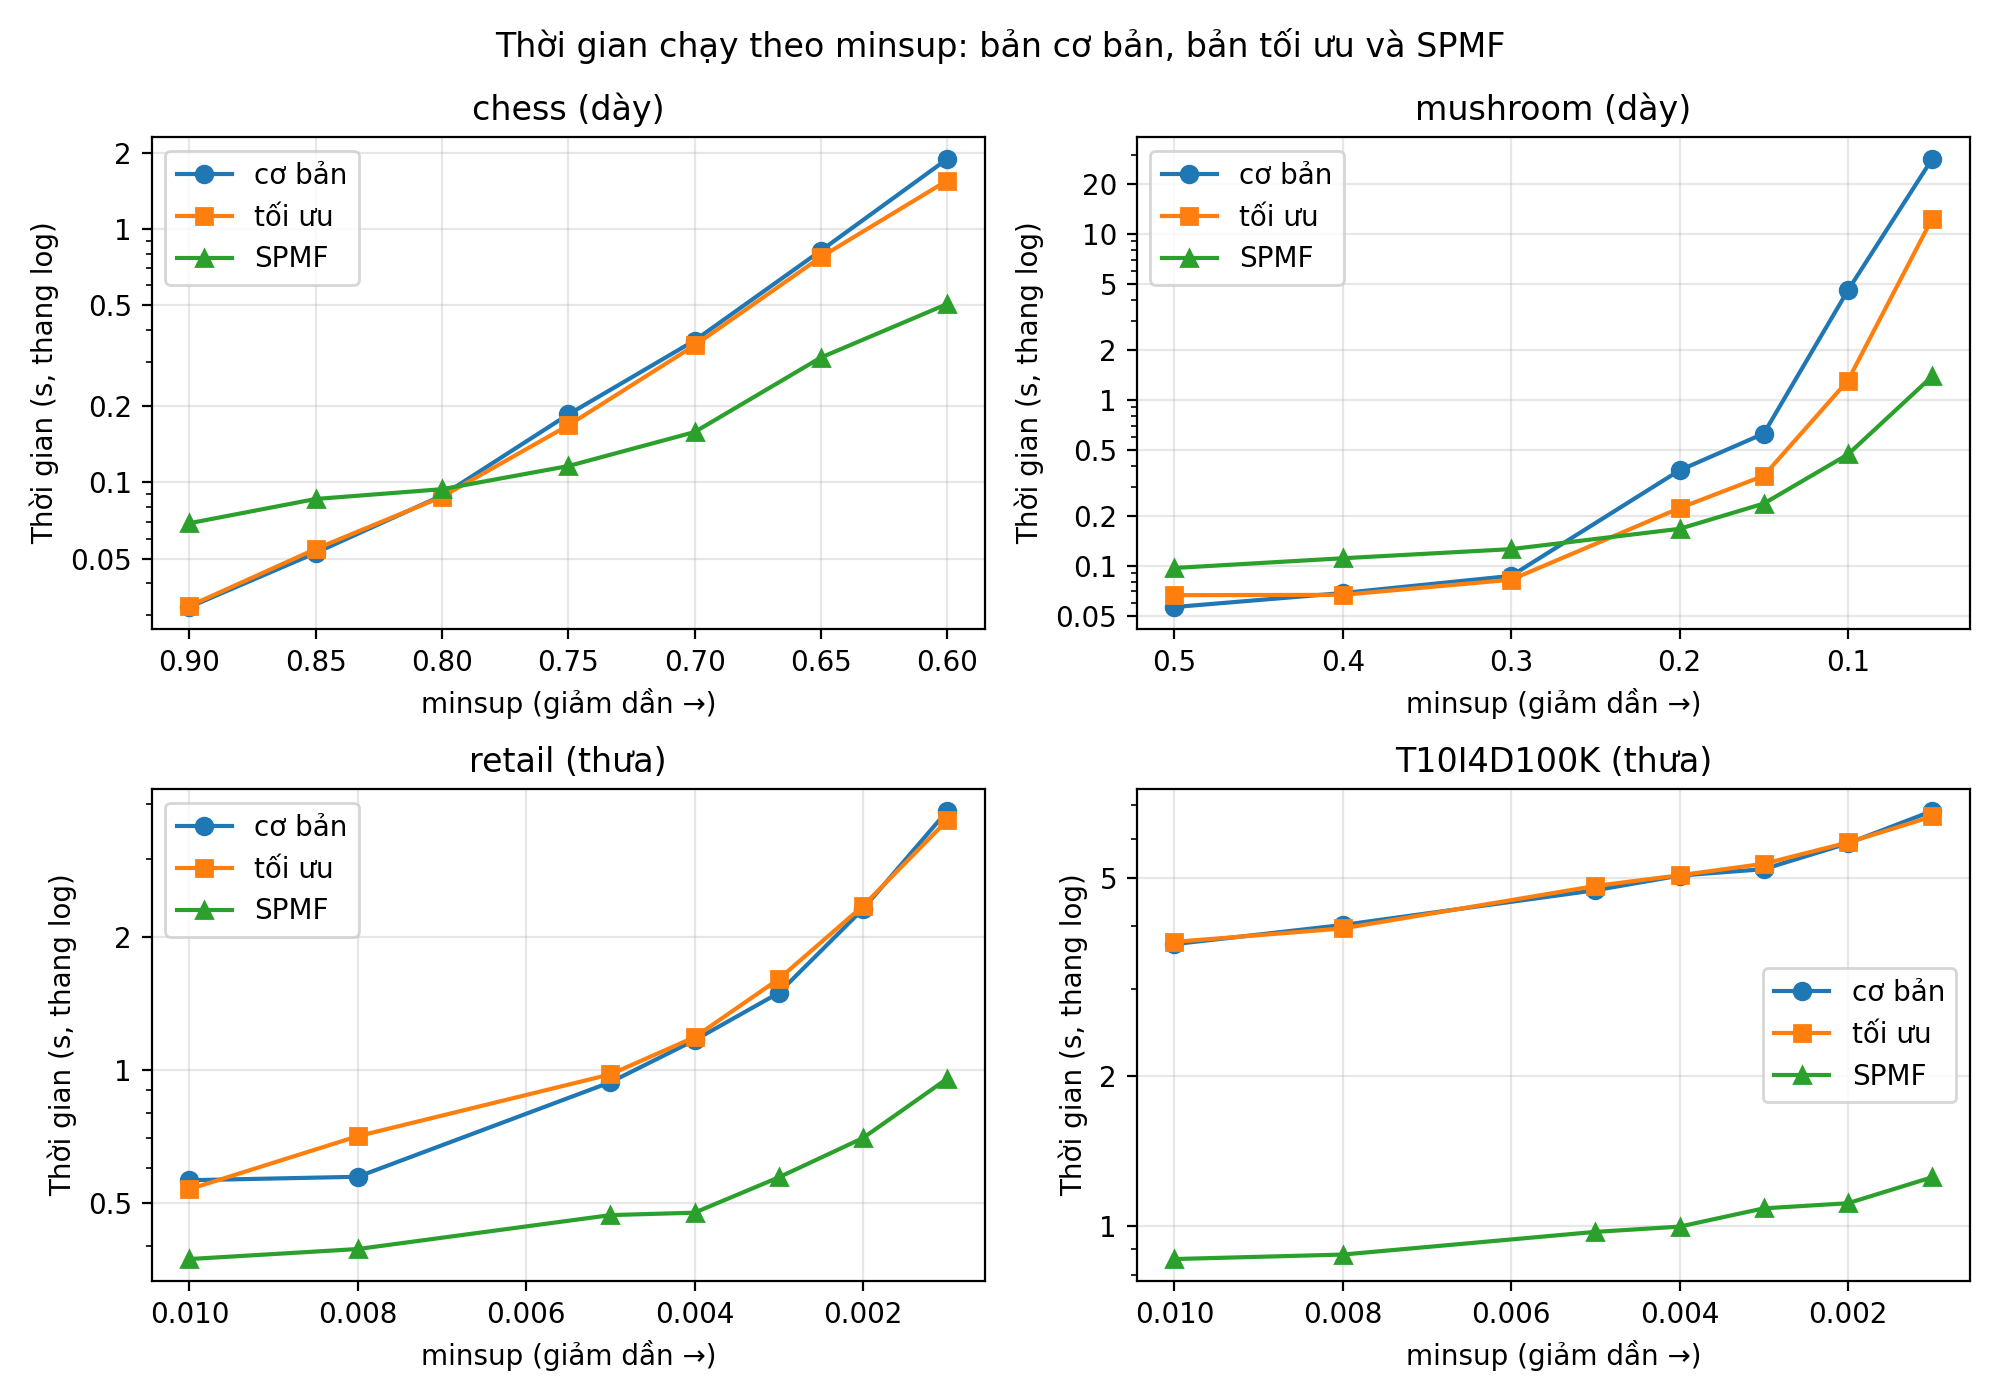

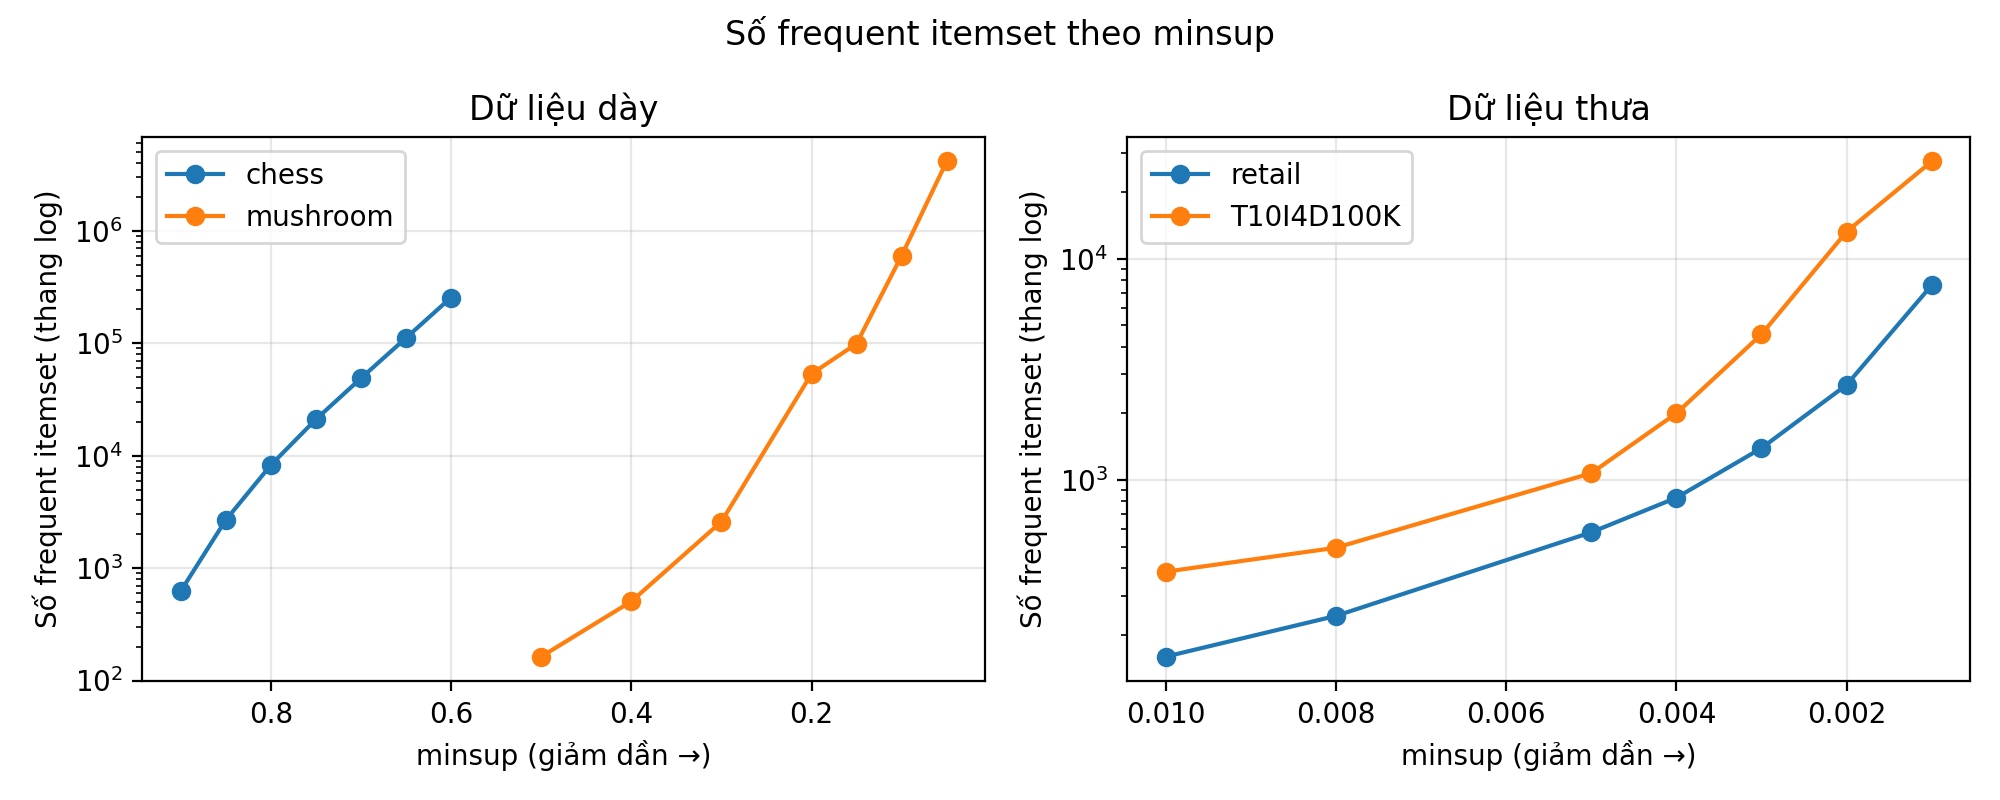

In [8]:
hinh("runtime")
hinh("itemsets")

**Nhận xét.**

- Hạ minsup thì số itemset tăng **theo hàm mũ** (Mushroom: 163 → 4,1 triệu khi minsup từ
  0,5 xuống 0,05). Trên **dữ liệu dày**, thời gian bám sát số itemset: chi phí chính là
  sinh itemset. Trên **dữ liệu thưa**, chi phí chính là dựng FP-tree gốc: T10I4D100K mất
  2,9 s dù chỉ có 385 itemset ở minsup 0,01.
- Tối ưu single path **có tác dụng rõ trên dữ liệu dày**: Mushroom 0,05 nhanh hơn bản cơ
  bản **3,7 lần** (ở 0,1 là 3,4 lần), Chess 1,2 lần. Trên **dữ liệu thưa** (Retail,
  T10I4D100K) gần như không đổi, vì conditional FP-tree hiếm khi chỉ còn một nhánh.
- Cài đặt Python chậm hơn SPMF (Java) khoảng **3,8–5,1 lần** ở minsup thấp nhất. Chênh lệch
  lớn nhất ở T10I4D100K 0,001 (5,1 lần) và Mushroom 0,05 (4,9 lần).


### 2.3. Bộ nhớ đỉnh

Đo bằng `tracemalloc` tại **minsup giữa** của mỗi CSDL, chỉ tính phần thuật toán.

,minsup,Cơ bản (MB),Tối ưu (MB),Thay đổi (%)
CSDL,,,,
chess,0.750,4.27,3.08,-27.9
mushroom,0.200,10.63,8.46,-20.4
retail,0.004,39.91,39.82,-0.2
T10I4D100K,0.004,204.65,204.66,0.0


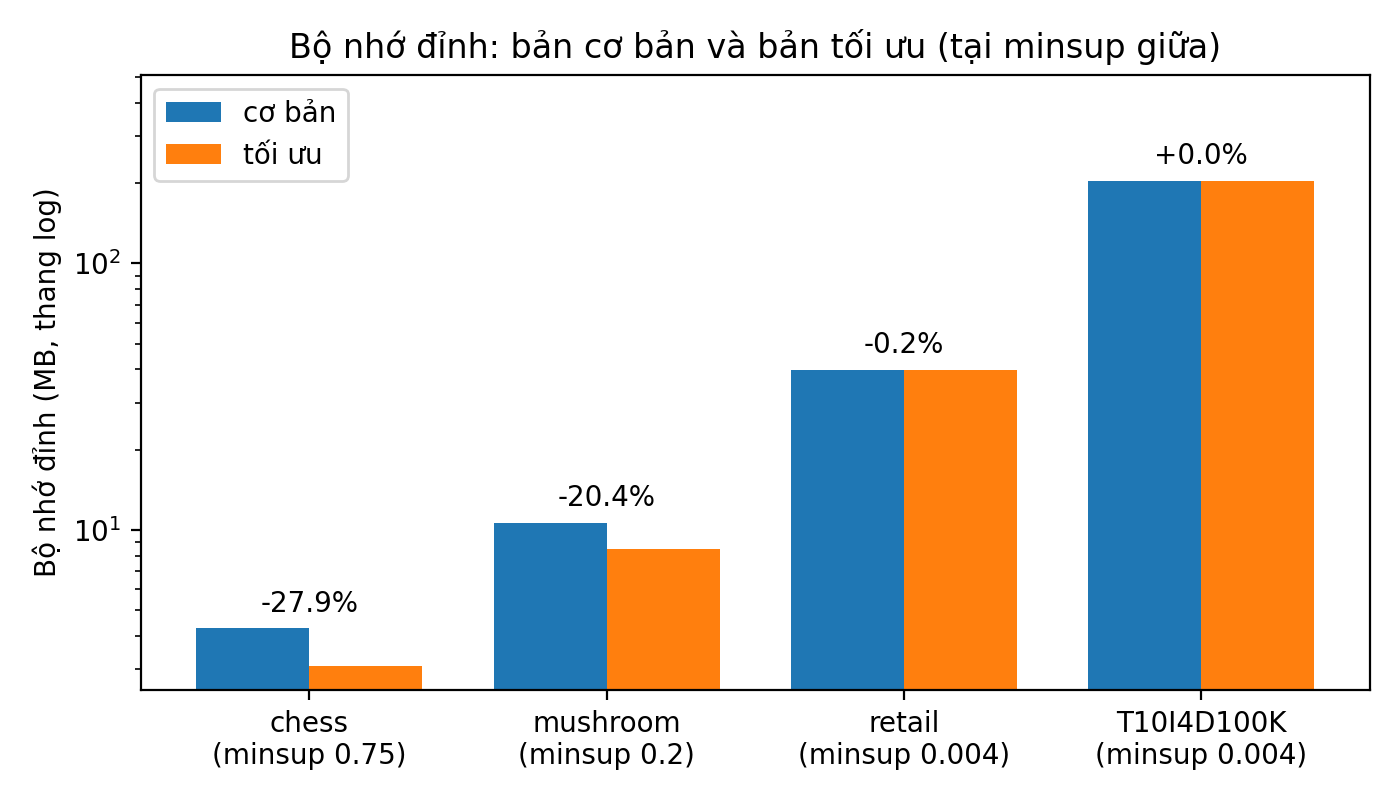

In [9]:
mem = pd.read_csv(f"{EXP}/memory.csv")
display(pd.DataFrame({
    "CSDL": mem["dataset"], "minsup": mem["minsup"],
    "Cơ bản (MB)": mem["peak_basic_mb"], "Tối ưu (MB)": mem["peak_opt_mb"],
    "Thay đổi (%)": ((mem["peak_opt_mb"] / mem["peak_basic_mb"] - 1) * 100).round(1),
}).set_index("CSDL"))
hinh("memory")

**Nhận xét.** Bản tối ưu giảm bộ nhớ khoảng **22–26%** trên Chess và Mushroom: khi gặp cây
một nhánh, nó liệt kê thẳng tổ hợp thay vì dựng thêm conditional FP-tree. Trên Retail và
T10I4D100K gần như không đổi, vì đỉnh bộ nhớ nằm ở **FP-tree gốc** (hàng chục nghìn giao
dịch, nhiều nhánh), phần mà tối ưu single path không chạm tới. Phần này được giảm nhờ tối ưu thứ hai: nút cây
dùng `__slots__` (cả hai bản đều dùng), giảm 12–14% bộ nhớ trên Retail và T10I4D100K so với
trước khi thêm (Retail 39,9 → 34,5 MB; T10I4D100K 204,7 → 179,0 MB).

### 2.4. Scalability: thời gian theo số giao dịch

Retail, minsup 0,004 cố định, lấy 10%, 25%, 50%, 75%, 100% số giao dịch (trộn một lần với
seed 42, các tập con lồng nhau).

,Số giao dịch,Số itemset,Thời gian (s)
Tỉ lệ dữ liệu,,,
10%,8816,850,0.1635
25%,22040,864,0.3216
50%,44081,837,0.7245
75%,66122,841,1.1970
100%,88162,831,1.5117


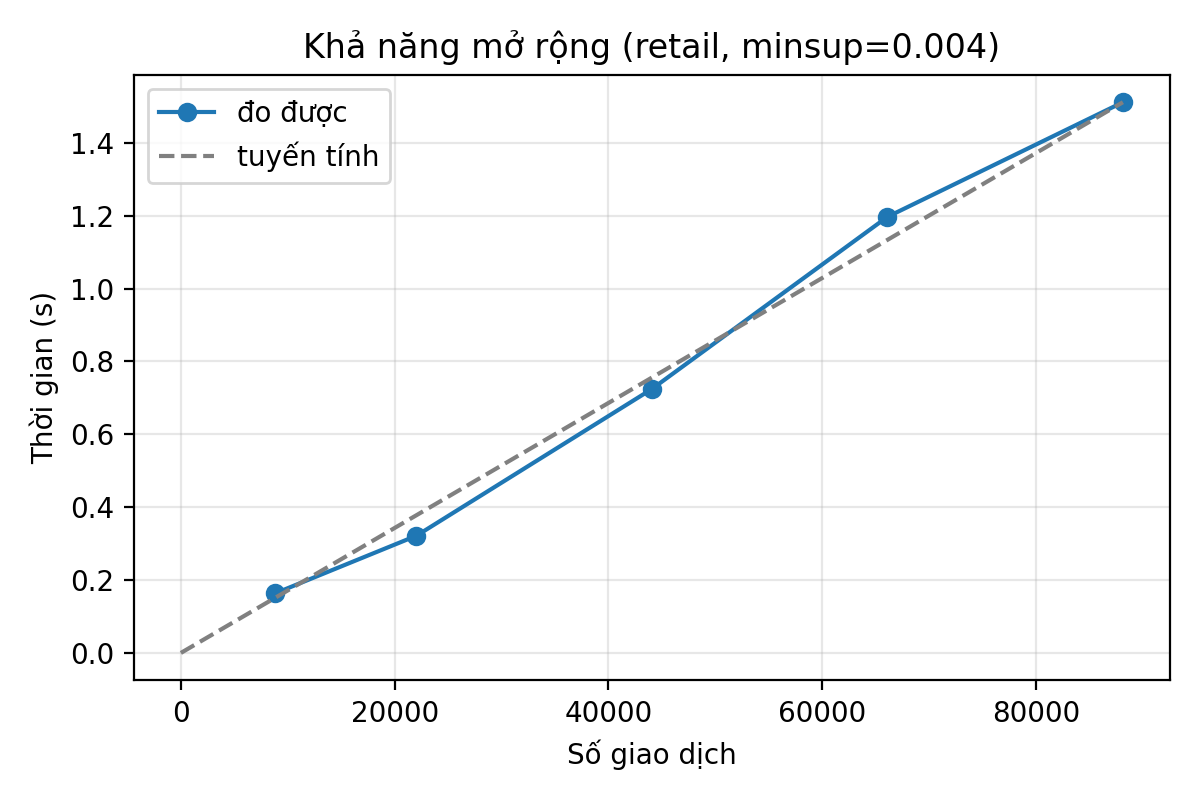

In [10]:
sc = pd.read_csv(f"{EXP}/scalability.csv")
display(pd.DataFrame({
    "Tỉ lệ dữ liệu": (sc["fraction"] * 100).astype(int).astype(str) + "%",
    "Số giao dịch": sc["transactions"], "Số itemset": sc["itemsets"],
    "Thời gian (s)": sc["t_opt_s"],
}).set_index("Tỉ lệ dữ liệu"))
hinh("scalability")

**Nhận xét.** Dữ liệu tăng **10 lần** (8.816 → 88.162 giao dịch) thì thời gian tăng khoảng
**11 lần** (0,10 → 1,05 s): **gần tuyến tính** theo số giao dịch. Số itemset gần như không đổi
(831–864) vì minsup là ngưỡng tương đối, nên thời gian tăng chủ yếu do phải quét và chèn
nhiều giao dịch hơn.

### 2.5. Thời gian theo độ dài giao dịch

CSDL tổng hợp: 10.000 giao dịch, 200 item, minsup 0,05, seed 42. Chỉ thay đổi **độ dài giao
dịch trung bình** (5 → 30).

,Số itemset,Thời gian (s)
Độ dài TB,,
5.03,37,0.0300
10.00,251,0.1077
14.94,1357,0.3562
20.00,6794,0.9100
24.96,31769,2.2900
29.95,145142,6.3324


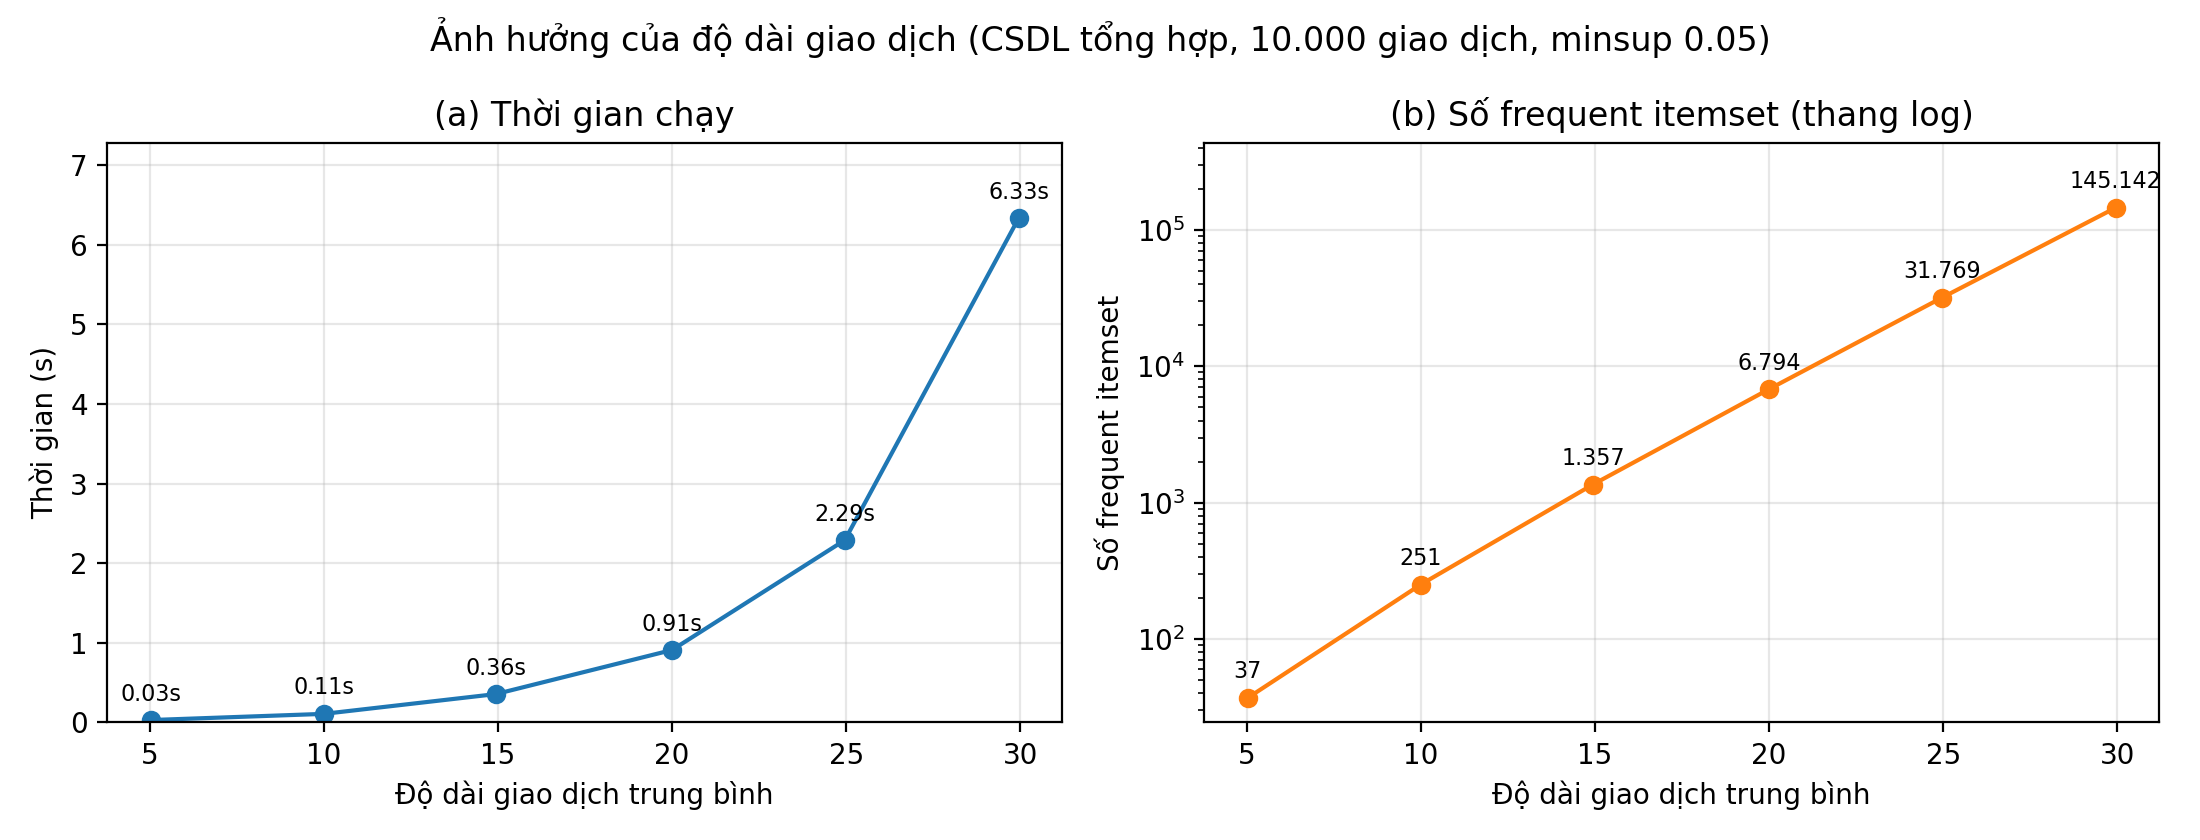

In [11]:
tx = pd.read_csv(f"{EXP}/txlen.csv")
display(pd.DataFrame({
    "Độ dài TB": tx["avg_len"], "Số itemset": tx["itemsets"], "Thời gian (s)": tx["t_opt_s"],
}).set_index("Độ dài TB"))
hinh("txlen")

**Nhận xét.** Độ dài tăng **6 lần** nhưng thời gian tăng khoảng **190 lần** (0,03 → 5,6 s) và
số itemset tăng khoảng **3.900 lần** (37 → 145.142): thời gian tăng **phi tuyến**. Giao dịch dài
$L$ có $2^L - 1$ tập con, nên số itemset phổ biến và độ sâu đệ quy cùng tăng nhanh. Đây là
lý do dữ liệu dày (Chess, độ dài 37) khó hơn nhiều so với dữ liệu thưa dù có ít giao dịch
hơn.

### 2.6. Tái lập nhanh

Chạy lại thực nghiệm thời gian trên Chess (khoảng 3 giây), ghi ra file riêng để không đè
lên số liệu chính thức. Số itemset phải trùng với bảng ở 2.1.

In [12]:
!{sys.executable} -m scripts.exp_runtime --dataset chess --runs 1 --skip-basic --skip-spmf --csv data/output/exp/runtime_colab.csv
moi = pd.read_csv("data/output/exp/runtime_colab.csv")
cu = rt[rt["dataset"] == "chess"]
print("Số itemset trùng với số liệu chính thức:",
      list(moi["itemsets"]) == list(cu["itemsets"]))

Bỏ qua 7 ca đã có trong data/output/exp/runtime_colab.csv.
Xong 0 ca, số liệu trong data/output/exp/runtime_colab.csv.
Số itemset trùng với số liệu chính thức: True


**Hướng tối ưu tiếp theo** (chi tiết ở Chương 2 của báo cáo): đổi cấu trúc nút từ object
Python sang mảng, để giảm bộ nhớ trên dữ liệu thưa, nơi FP-tree gốc chiếm đỉnh bộ nhớ;
không dựng lại conditional tree khi prefix path chỉ còn một giao dịch; chỉ khai thác
closed/maximal itemset khi minsup thấp.

## 3. Ứng dụng 1: Phân tích giỏ hàng và sinh luật kết hợp

In [13]:
import time
from collections import Counter

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from src.algorithm.fpgrowth import fpgrowth
from src.apps.basket import (describe, load_dataset, read_baskets,
                             shuffle_keep_marginals)
from src.config import (APP1_MINCONF, APP1_MINCONFS, APP1_MINSUP, APP1_MINSUPS,
                        APP1_MINSUP_RETAIL, APP1_SHUFFLES, GROCERIES, SEED,
                        to_min_count)
from src.rules import format_rule, generate_rules, rule_names, sort_rules
from src.utils import encode, invert_code

# Bảng màu và kiểu đồ thị dùng chung cho mọi hình, để các hình trong báo cáo
# trông như một bộ. Dải RAMP là MỘT màu đậm dần, dùng cho đại lượng có thứ tự
# (minsup); hai màu BLUE/ORANGE dùng khi có hai chuỗi không so được bậc.
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
SEQ = LinearSegmentedColormap.from_list("blue_seq", [
    "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 110,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK_2,
    "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,        # lưới nằm DƯỚI dữ liệu
    "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 9,
    "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 5,
    "figure.autolayout": True,                        # không bị cắt nhãn
})
pd.set_option("display.width", 140)

print("python", sys.version.split()[0], "| matplotlib", matplotlib.__version__,
      "| pandas", pd.__version__)
print("Ngưỡng mặc định lấy từ src/config.py:",
      f"minsup {APP1_MINSUP}, minconf {APP1_MINCONF}, seed {SEED}")

python 3.13.9 | matplotlib 3.10.6 | pandas 2.3.3
Ngưỡng mặc định lấy từ src/config.py: minsup 0.01, minconf 0.3, seed 42


### 3.1. Dữ liệu: CSDL Groceries

`data/app1/groceries.csv` — dữ liệu giỏ hàng thật của một cửa hàng bán lẻ, là bộ
`Groceries` đi kèm gói R `arules` (Hahsler, Grün, Hornik 2005). Mỗi dòng là một
giỏ, các món cách nhau bằng dấu phẩy, item là **tên đọc được**:

```
citrus fruit,semi-finished bread,margarine,ready soups
tropical fruit,yogurt,coffee
whole milk
```

**Vì sao chọn bộ này chứ không chỉ dùng `retail.txt` đã có trong repo:** item của
Retail đã bị ẩn danh thành số, mà đề yêu cầu *giải thích ý nghĩa kinh doanh* của
luật — không có tên món thì không giải thích được gì. Mục 3.9 vẫn chạy lại toàn bộ
quy trình trên Retail để cho thấy phương pháp làm việc được ở quy mô 88.162 giỏ.

**Vì sao bộ này dùng để kiểm chứng được:** số liệu của Groceries đã được công bố
rộng rãi, nên nhóm có mốc để đối chiếu cài đặt của mình. Notebook sẽ kiểm bốn
mốc: `support(whole milk)`, giá trị của hai luật kinh điển, và số luật ở hai cặp
ngưỡng. Nhóm đối chiếu **kết quả số**, không đọc và không sao chép code của
`arules`.

In [14]:
baskets = read_baskets(GROCERIES)
stats = describe(baskets)

print(f"{stats['transactions']} giỏ | {stats['items']} mặt hàng phân biệt "
      f"| {stats['occurrences']} lượt mua")
print(f"độ dài giỏ: trung bình {stats['avg_len']:.4f}, nhỏ nhất {stats['min_len']}, "
      f"lớn nhất {stats['max_len']} | độ dày {stats['density']:.4f}")
print("\n5 giỏ đầu:")
for i, basket in enumerate(baskets[:5], start=1):
    print(f"  {i}. " + ", ".join(basket))

9835 giỏ | 169 mặt hàng phân biệt | 43367 lượt mua
độ dài giỏ: trung bình 4.4095, nhỏ nhất 1, lớn nhất 32 | độ dày 0.0261

5 giỏ đầu:
  1. citrus fruit, semi-finished bread, margarine, ready soups
  2. tropical fruit, yogurt, coffee
  3. whole milk
  4. pip fruit, yogurt, cream cheese, meat spreads
  5. other vegetables, whole milk, condensed milk, long life bakery product


In [15]:
# 10 mặt hàng bán chạy nhất. Con số này quan trọng cho mục 3.6: whole milk có mặt
# trong 1/4 số giỏ, nên mọi luật dẫn tới nó đều có confidence cao sẵn.
dem = Counter(item for basket in baskets for item in basket)
pd.DataFrame([(ten, so, round(so / len(baskets), 4)) for ten, so in dem.most_common(10)],
             columns=["mặt hàng", "số giỏ", "support"],
             index=range(1, 11))

,mặt hàng,số giỏ,support
1,whole milk,2513,0.2555
2,other vegetables,1903,0.1935
3,rolls/buns,1809,0.1839
4,soda,1715,0.1744
5,yogurt,1372,0.1395
6,bottled water,1087,0.1105
7,root vegetables,1072,0.1090
8,tropical fruit,1032,0.1049
9,shopping bags,969,0.0985
10,sausage,924,0.0940


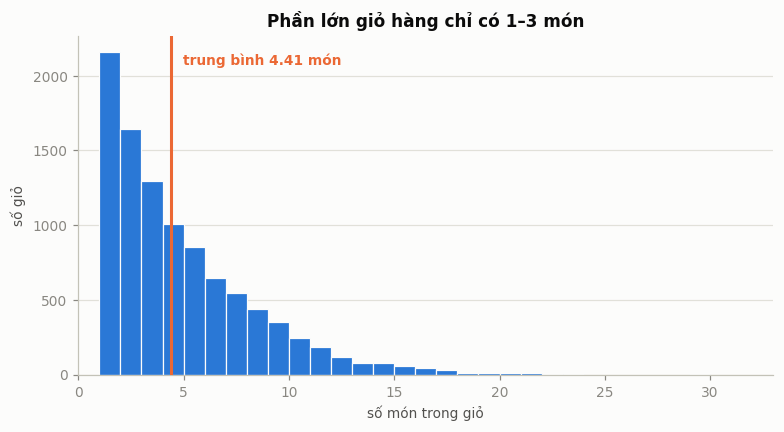

51.9% số giỏ có nhiều nhất 3 món.
Hệ quả: CSDL này rất THƯA (độ dày 2,6%), nên minsup phải đặt rất thấp —
một luật phủ 1% số giỏ ở đây đã là luật đáng chú ý.


In [16]:
lengths = [len(basket) for basket in baskets]

fig, ax = plt.subplots()
ax.hist(lengths, bins=range(1, stats["max_len"] + 2), color=BLUE,
        edgecolor=SURFACE, linewidth=0.8)
ax.axvline(stats["avg_len"], color=ORANGE, linewidth=2, zorder=3)
ax.annotate(f"trung bình {stats['avg_len']:.2f} món",
            xy=(stats["avg_len"], 2100), xytext=(8, 0),
            textcoords="offset points", color=ORANGE, fontweight="bold", va="center")
ax.set_title("Phần lớn giỏ hàng chỉ có 1–3 món")
ax.set_xlabel("số món trong giỏ")
ax.set_ylabel("số giỏ")
ax.set_xlim(0, 33)
ax.grid(axis="x", visible=False)
plt.show()

print(f"{sum(1 for n in lengths if n <= 3) / len(lengths):.1%} số giỏ có nhiều nhất 3 món.")
print("Hệ quả: CSDL này rất THƯA (độ dày 2,6%), nên minsup phải đặt rất thấp —")
print("một luật phủ 1% số giỏ ở đây đã là luật đáng chú ý.")

### 3.2. Biến đổi dữ liệu thành giao dịch

Hai bước, đúng như đề yêu cầu phải nêu rõ:

1. **Một giỏ là một giao dịch.** Ở bộ này mỗi dòng đã là một giỏ nên không phải
   gộp gì. Nếu dữ liệu ở dạng mỗi dòng một món (ví dụ bộ Kaggle
   `Groceries_dataset.csv` có cột `Member_number, Date, itemDescription`) thì
   phải gộp theo cặp (khách, ngày) trước — bước đó mới là chỗ dễ sai.
2. **Mã hoá item sang số nguyên** bằng `src.utils.encode`, vì `fpgrowth` của
   nhóm làm việc trên item số (đúng định dạng SPMF). `encode` gán số theo **tên
   đã sắp a–z**, nên cùng một file dữ liệu luôn cho cùng một bảng mã — điều kiện
   để kết quả tái lập được. Đổi ngược về tên bằng `invert_code`.

Mỗi giao dịch chỉ tính một item một lần (`fpgrowth` dùng `set(transaction)` khi
đếm), nên dữ liệu có món lặp vẫn cho support đúng.

In [17]:
encoded, code = encode(baskets)
name_of = invert_code(code)
N = len(encoded)

print(f"N = {N} giao dịch, {len(code)} mã item")
print("\nVài mã:")
for ten in list(code)[:3] + ["whole milk", "yogurt"]:
    print(f"  {code[ten]:>4}  <-  {ten}")
print("\nGiỏ đầu tiên:", baskets[0])
print("          ->  ", encoded[0])

# đổi ngược lại phải về đúng dữ liệu gốc (so theo tập, vì encode không giữ thứ tự)
assert [sorted(b) for b in baskets] == [sorted(name_of[i] for i in t) for t in encoded]
print("\nencode -> decode khớp dữ liệu gốc.")

N = 9835 giao dịch, 169 mã item

Vài mã:
     1  <-  Instant food products
     2  <-  UHT-milk
     3  <-  abrasive cleaner
   167  <-  whole milk
   168  <-  yogurt

Giỏ đầu tiên: ['citrus fruit', 'semi-finished bread', 'margarine', 'ready soups']
          ->   [32, 134, 90, 120]

encode -> decode khớp dữ liệu gốc.


### 3.3. Khai thác tập phổ biến bằng FP-Growth của nhóm

`min_count` là support **tuyệt đối**, tính bằng `to_min_count` trong
`src/config.py` (`ceil(round(minsup * N, 9))`) — đúng cách SPMF làm tròn lên, nên
kết quả so khớp được với SPMF ở Chương 1 và 2.

In [18]:
minsup = APP1_MINSUP
min_count = to_min_count(minsup, N)

start = time.perf_counter()
itemsets = fpgrowth(encoded, min_count)
t_mine = time.perf_counter() - start

by_size = Counter(len(itemset) for itemset in itemsets)
print(f"minsup {minsup} -> min_count {min_count} (một luật phải phủ ít nhất "
      f"{min_count} giỏ)")
print(f"{len(itemsets)} tập phổ biến trong {t_mine:.3f}s\n")
print(pd.DataFrame(sorted(by_size.items()), columns=["số item", "số tập phổ biến"])
      .to_string(index=False))

sup_wm = itemsets[(code["whole milk"],)]
print(f"\nMỐC 1 — support(whole milk) = {sup_wm}/{N} = {sup_wm / N:.5f}"
      f"   (giá trị công bố: 2513, tức 0,25552)")

minsup 0.01 -> min_count 99 (một luật phải phủ ít nhất 99 giỏ)
333 tập phổ biến trong 0.101s

 số item  số tập phổ biến
       1               88
       2              213
       3               32

MỐC 1 — support(whole milk) = 2513/9835 = 0.25552   (giá trị công bố: 2513, tức 0,25552)


### 3.4. Sinh luật kết hợp

Với mỗi tập phổ biến $Z$ có từ 2 item trở lên, cắt $Z$ thành $X$ (bên trái) và
$Y$ (bên phải) rồi tính bốn đo lường. Gọi $N$ là số giao dịch và $sup(S)$ là số
giao dịch chứa trọn $S$:

$$
\text{support} = \frac{sup(Z)}{N},\qquad
\text{confidence} = \frac{sup(Z)}{sup(X)},\qquad
\text{lift} = \frac{\text{confidence}}{sup(Y)/N},\qquad
\text{leverage} = \frac{sup(Z)}{N} - \frac{sup(X)}{N}\cdot\frac{sup(Y)}{N}
$$

Mỗi đo lường trả lời một câu hỏi khác nhau:

| Đo lường | Câu hỏi | Đọc thế nào |
|---|---|---|
| support | Luật này phủ bao nhiêu giỏ? | Có đáng làm không |
| confidence | Mua $X$ thì bao nhiêu phần mua $Y$? | Dự đoán được không |
| lift | So với mua $Y$ một cách độc lập thì hơn bao nhiêu lần? | Có thật là liên quan không (1 = độc lập) |
| leverage | Quan hệ đó đổi ra bao nhiêu phần giỏ? | Hiệu ứng tuyệt đối |

`sup(X)` và `sup(Y)` luôn tra được trong dict kết quả: $X$ và $Y$ là tập con thực
sự của $Z$ phổ biến, nên theo tính chất đóng xuống của Apriori chúng cũng phổ
biến, và `fpgrowth` trả về **toàn bộ** tập phổ biến kể cả tập một phần tử.

Mặc định `max_consequent=1` — bên phải chỉ một món. Đây là dạng dùng được trong
bán lẻ ("khách mua X thì gợi ý thêm Y") và cũng là dạng đọc được; đặt `None` thì
xét cả $2^k - 2$ cách tách.

In [19]:
start = time.perf_counter()
rules = generate_rules(itemsets, N, APP1_MINCONF)
t_rules = time.perf_counter() - start

print(f"minconf {APP1_MINCONF}: {len(rules)} luật, sinh trong {t_rules:.3f}s")
print(f"minconf 0.5 : {len(generate_rules(itemsets, N, 0.5))} luật")
print(f"\nMỐC 2 — minsup 0,01 với minconf 0,5 cho đúng 15 luật (giá trị công bố: 15)")


def bang_luat(rules, n=10, by="lift"):
    """Bảng n luật đứng đầu theo một tiêu chí, đã đổi số về tên món."""
    rows = [{
        "luật": format_rule(rule, name_of),
        "giỏ": rule.support_count,
        "support": round(rule.support, 4),
        "confidence": round(rule.confidence, 3),
        "lift": round(rule.lift, 3),
        "leverage": round(rule.leverage, 5),
    } for rule in sort_rules(rules, by=by)[:n]]
    return pd.DataFrame(rows, index=range(1, len(rows) + 1))


def tim_luat(rules, trai, phai):
    """Tìm đúng một luật theo tên món."""
    for rule in rules:
        left, right = rule_names(rule, name_of)
        if set(left) == set(trai) and set(right) == set(phai):
            return rule
    raise KeyError(f"không có luật {trai} -> {phai} ở ngưỡng hiện tại")


moc = tim_luat(rules, ["other vegetables", "yogurt"], ["whole milk"])
print(f"\nMỐC 3 — {format_rule(moc, name_of)}")
print(f"  nhóm tính: support {moc.support:.5f} | confidence {moc.confidence:.5f} "
      f"| lift {moc.lift:.5f}")
print(f"  công bố:   support 0,02226 | confidence 0,51280 | lift 2,00720")

minconf 0.3: 125 luật, sinh trong 0.002s
minconf 0.5 : 15 luật

MỐC 2 — minsup 0,01 với minconf 0,5 cho đúng 15 luật (giá trị công bố: 15)

MỐC 3 — {other vegetables, yogurt} -> {whole milk}
  nhóm tính: support 0.02227 | confidence 0.51288 | lift 2.00723
  công bố:   support 0,02226 | confidence 0,51280 | lift 2,00720


### 3.5. Top 10 luật theo lift và ý nghĩa kinh doanh

Đây là sản phẩm chính mà đề yêu cầu.

In [20]:
pd.set_option("display.max_colwidth", None)    # hiện đủ nội dung luật, không bị cắt "..."
bang_luat(rules, 10, by="lift")

,luật,giỏ,support,confidence,lift,leverage
1,"{citrus fruit, other vegetables} -> {root vegetables}",102,0.0104,0.359,3.295,0.00722
2,"{other vegetables, tropical fruit} -> {root vegetables}",121,0.0123,0.343,3.145,0.00839
3,{beef} -> {root vegetables},171,0.0174,0.331,3.040,0.01167
4,"{citrus fruit, root vegetables} -> {other vegetables}",102,0.0104,0.586,3.030,0.00695
5,"{root vegetables, tropical fruit} -> {other vegetables}",121,0.0123,0.585,3.021,0.00823
6,"{other vegetables, whole milk} -> {root vegetables}",228,0.0232,0.310,2.842,0.01503
7,"{curd, whole milk} -> {yogurt}",99,0.0101,0.385,2.761,0.00642
8,"{rolls/buns, root vegetables} -> {other vegetables}",120,0.0122,0.502,2.595,0.00750
9,"{root vegetables, yogurt} -> {other vegetables}",127,0.0129,0.500,2.584,0.00792
10,"{tropical fruit, whole milk} -> {yogurt}",149,0.0151,0.358,2.568,0.00925


#### Diễn giải

Mười luật này không phải mười chuyện rời rạc — chúng rơi vào **ba nhóm hành vi**,
và mỗi nhóm cho một việc làm được:

**Nhóm 1 — giỏ nấu ăn tươi (7 trong 10 luật: 1, 2, 4, 5, 6, 8, 9).**
`root vegetables`, `other vegetables`, `citrus fruit`, `tropical fruit` kéo nhau
rất mạnh (lift 2,6–3,3). Khách mua rau củ hầu như không mua đúng một loại: họ
đang mua nguyên liệu cho một bữa nấu ở nhà, nên lấy cả củ, cả rau lá, cả trái
cây trong một lượt. Đáng chú ý là luật 1 và 4 là **hai cách tách khác nhau của
cùng một tập phổ biến 3 món** `{citrus fruit, other vegetables, root vegetables}`
— cả hai cách tách đều lọt top 10, nghĩa là ba món này đi cùng nhau thành một
cụm chứ không phải "món A dẫn tới món B". Luật 2 và 5 cũng là một cặp như vậy
với `tropical fruit` thay cho `citrus fruit`.

> **Việc làm được:** xếp các quầy rau củ và trái cây liền nhau thành một khu
> "nguyên liệu nấu ăn". Nếu đang để trái cây ở đầu kia siêu thị thì đó là đang
> cắt đôi một giỏ hàng tự nhiên.

**Nhóm 2 — giỏ món hầm (luật 3).** `beef -> root vegetables`, lift 3,04. Đây là
luật **duy nhất trong top 10 có bên trái chỉ một món**, nên cũng là luật dễ dùng
nhất: chỉ cần biết khách đã lấy thịt bò là đã gợi ý được. Thịt bò và củ là công
thức món hầm kinh điển.

> **Việc làm được:** đặt kệ củ nhỏ ngay tại quầy thịt, hoặc combo "thịt bò + củ"
> kèm công thức. Hiệu ứng ước lượng được ở ô dưới.

**Nhóm 3 — giỏ bữa sáng sữa (luật 7, 10).** `curd + whole milk -> yogurt` và
`tropical fruit + whole milk -> yogurt`, lift 2,6–2,8. Người mua đồ sữa mua theo
cả nhóm, và trái cây nhiệt đới đi cùng sữa chua là mô-típ bữa sáng.

> **Việc làm được:** đưa sữa chua về cạnh quầy sữa thay vì để ở khu tráng miệng.

**Một quan sát về quy mô, cần nói thẳng:** support của cả 10 luật chỉ 1–2,3%,
tức mỗi luật phủ khoảng 100–230 giỏ trong 9.835 giỏ. Ở bán lẻ đó là chuyện bình
thường — không có luật nào phủ phần lớn hoá đơn, vì giỏ trung bình chỉ 4,4 món
trên 169 mặt hàng. Giá trị của phân tích này là **nhiều luật nhỏ cộng lại**, chứ
không phải một luật lớn. Cột `leverage` nói đúng điều đó: luật 6
(`other vegetables + whole milk -> root vegetables`) có lift thấp nhất trong top
10 nhưng leverage **cao nhất**, vì nó phủ 228 giỏ — nếu chỉ được chọn một luật để
làm thì chọn luật này, không phải luật số 1.

In [21]:
# Ước lượng hiệu ứng của một combo, dựa trên đúng số liệu ở trên.
beef = tim_luat(rules, ["beef"], ["root vegetables"])
sup_beef = itemsets[(code["beef"],)]
sup_rv = itemsets[(code["root vegetables"],)]

ky_vong_doc_lap = sup_beef * sup_rv / N          # nếu hai món độc lập
print(f"Giỏ có beef: {sup_beef} | giỏ có root vegetables: {sup_rv}")
print(f"Giỏ có cả hai: {beef.support_count}")
print(f"Nếu hai món độc lập thì chỉ còn khoảng {ky_vong_doc_lap:.0f} giỏ.")
print(f"=> {beef.support_count - ky_vong_doc_lap:.0f} giỏ 'tăng thêm' so với ngẫu nhiên, "
      f"tức {beef.leverage:.2%} tổng số giỏ.")
print(f"\nLeverage cao nhất trong top 10 theo lift:")
print(bang_luat(rules, 10).sort_values("leverage", ascending=False)
      .head(3)[["luật", "support", "lift", "leverage"]].to_string())

Giỏ có beef: 516 | giỏ có root vegetables: 1072
Giỏ có cả hai: 171
Nếu hai món độc lập thì chỉ còn khoảng 56 giỏ.
=> 115 giỏ 'tăng thêm' so với ngẫu nhiên, tức 1.17% tổng số giỏ.

Leverage cao nhất trong top 10 theo lift:
                                                   luật  support   lift  leverage
6   {other vegetables, whole milk} -> {root vegetables}   0.0232  2.842   0.01503
3                           {beef} -> {root vegetables}   0.0174  3.040   0.01167
10             {tropical fruit, whole milk} -> {yogurt}   0.0151  2.568   0.00925


### 3.6. Vì sao xếp theo lift chứ không phải confidence

Đề yêu cầu xếp top 10 theo lift. Lý do nằm ở chính dữ liệu này: `whole milk` có
mặt trong **1/4 số giỏ**. Bất kỳ luật nào dẫn tới `whole milk` cũng có confidence
cao sẵn, không cần hai món có quan hệ gì — đoán "khách sẽ mua sữa" thì đúng
25,6% số lần ngay cả khi chẳng biết gì về giỏ.

Trong dữ liệu này có một cặp đối chứng gần như hoàn hảo cho chuyện đó.

In [22]:
cap = [tim_luat(rules, ["curd", "yogurt"], ["whole milk"]),
       tim_luat(rules, ["citrus fruit", "root vegetables"], ["other vegetables"])]

sup_ov = itemsets[(code["other vegetables"],)]
print(f"support(whole milk)       = {sup_wm / N:.4f}")
print(f"support(other vegetables) = {sup_ov / N:.4f}\n")

pd.DataFrame([{
    "luật": format_rule(rule, name_of),
    "support": round(rule.support, 4),
    "confidence": round(rule.confidence, 3),
    "lift": round(rule.lift, 3),
} for rule in cap], index=["dẫn tới món rất phổ biến", "dẫn tới món ít phổ biến hơn"])

support(whole milk)       = 0.2555
support(other vegetables) = 0.1935



,luật,support,confidence,lift
dẫn tới món rất phổ biến,"{curd, yogurt} -> {whole milk}",0.0101,0.582,2.279
dẫn tới món ít phổ biến hơn,"{citrus fruit, root vegetables} -> {other vegetables}",0.0104,0.586,3.030


In [23]:
# Nếu xếp theo confidence thì top 5 bị món bán chạy chiếm chỗ:
bang_luat(rules, 5, by="confidence")

,luật,giỏ,support,confidence,lift,leverage
1,"{citrus fruit, root vegetables} -> {other vegetables}",102,0.0104,0.586,3.030,0.00695
2,"{root vegetables, tropical fruit} -> {other vegetables}",121,0.0123,0.585,3.021,0.00823
3,"{curd, yogurt} -> {whole milk}",99,0.0101,0.582,2.279,0.00565
4,"{butter, other vegetables} -> {whole milk}",113,0.0115,0.574,2.245,0.00637
5,"{root vegetables, tropical fruit} -> {whole milk}",118,0.0120,0.570,2.231,0.00662


Hai luật ở bảng trên có confidence **gần như bằng nhau** (0,582 so với 0,586)
nhưng lift lệch tới 33%, chỉ vì `whole milk` phổ biến hơn `other vegetables`
(0,2555 so với 0,1935). Nếu xếp theo confidence, phần lớn top 5 là các luật dẫn
tới `whole milk` — tức là ta đang phát hiện lại "sữa bán chạy", một điều đã biết
từ bảng ở mục 3.1, chứ không phát hiện quan hệ nào mới.

Kết luận thực hành: **lift để tìm ra quan hệ, support và leverage để quyết định
có làm hay không, confidence để ước lượng tỉ lệ thành công khi gợi ý.** Bỏ một
trong bốn là ra quyết định sai — xem lại luật 6 ở mục 3.5.

### 3.7. Null model: các mẫu này có thật, hay chỉ do vài món bán chạy?

Mục 3.6 cho thấy độ bán chạy của từng món bóp méo confidence. Câu hỏi tiếp theo
nghiêm trọng hơn: **nếu chỉ riêng độ bán chạy của từng món đã đủ sinh ra những
luật như trên thì sao?** Khi đó cả phân tích này vô nghĩa.

Cách kiểm: dựng một CSDL đối chứng (*null model*) bằng cách **trộn các món giữa
các giỏ**, nhưng giữ **nguyên vẹn**:

- tần suất mỗi món (`whole milk` vẫn có mặt đúng 2.513 lần),
- độ dài mỗi giỏ (giỏ 3 món vẫn 3 món).

Chỉ có **việc món nào đi với món nào** bị phá. Nếu các luật ở mục 3.5 chỉ là hệ quả
của độ bán chạy, dữ liệu trộn phải cho ra lượng luật và mức lift tương đương.

Cách trộn: làm phẳng toàn bộ 43.367 lượt mua thành một danh sách, trộn một lần
bằng `random.Random(seed)`, rồi cắt lại theo đúng độ dài từng giỏ
(`shuffle_keep_marginals`). Seed cố định nên chạy lại ra đúng số cũ. Hạn chế đã
biết: cách này có thể đặt hai lượt của cùng một món vào một giỏ, nên dữ liệu trộn
hơi loãng hơn thật — lệch này chỉ làm null model *dễ thắng hơn*, nên kết luận
không bị thổi phồng.

In [24]:
def do_mot_csdl(data, nhan):
    its = fpgrowth(data, min_count)
    rs = generate_rules(its, N, APP1_MINCONF)
    lifts = [rule.lift for rule in rs]
    return {"dữ liệu": nhan,
            "tập phổ biến": len(its),
            "số luật": len(rs),
            "lift lớn nhất": round(max(lifts), 3) if lifts else 0.0,
            "số luật lift > 1,5": sum(1 for lift in lifts if lift > 1.5)}


hang = [do_mot_csdl(encoded, "THẬT")]
for i in range(APP1_SHUFFLES):
    hang.append(do_mot_csdl(shuffle_keep_marginals(encoded, SEED + i),
                            f"trộn, seed {SEED + i}"))

null_df = pd.DataFrame(hang)
null_df

,dữ liệu,tập phổ biến,số luật,lift lớn nhất,"số luật lift > 1,5"
0,THẬT,333,125,3.295,108
1,"trộn, seed 42",246,9,1.662,2
2,"trộn, seed 43",253,11,1.726,4
3,"trộn, seed 44",245,13,1.743,8
4,"trộn, seed 45",245,10,1.733,5
5,"trộn, seed 46",251,13,1.780,5


In [25]:
thuc = null_df.iloc[0]
tron = null_df.iloc[1:]

print("Dữ liệu thật so với trung vị các lần trộn:")
for cot in ("số luật", "lift lớn nhất", "số luật lift > 1,5"):
    trung_vi = tron[cot].median()
    ti_so = thuc[cot] / trung_vi if trung_vi else float("inf")
    print(f"  {cot:<20} thật {thuc[cot]:>9.3f} | trộn {trung_vi:>9.3f} "
          f"| gấp {ti_so:>7.2f} lần")

Dữ liệu thật so với trung vị các lần trộn:
  số luật              thật   125.000 | trộn    11.000 | gấp   11.36 lần
  lift lớn nhất        thật     3.295 | trộn     1.733 | gấp    1.90 lần
  số luật lift > 1,5   thật   108.000 | trộn     5.000 | gấp   21.60 lần


Dữ liệu thật có **125 luật**, lift cao nhất **3,30**, và **108 luật** có lift trên
1,5. Năm lần trộn chỉ cho khoảng **11 luật**, lift cao nhất khoảng **1,73**, và
chừng **5 luật** vượt lift 1,5 — tức là **gấp hơn 20 lần** ở thống kê tách tốt
nhất. Vì phép trộn đã giữ nguyên độ bán chạy của từng món, phần chênh lệch này
chỉ còn một cách giải thích: **các món thật sự được khách mua cùng nhau.** Các
luật ở mục 3.5 không phải hiện tượng giả do vài món bán chạy.

Chú ý: dữ liệu trộn vẫn cho ra 245–253 tập phổ biến, gần bằng 333 của dữ liệu
thật. Tức là **số tập phổ biến không phải thống kê tốt để đánh giá** — nó phần
lớn do độ bán chạy của từng món quyết định. Phải nhìn vào số *luật* và vào phân
bố *lift*. Mục 3.9 còn cho thấy ngay cả ngưỡng "lift > 1,5" cũng mất tác dụng khi
CSDL quá thưa.

### 3.8. Ảnh hưởng của minsup và minconf

Hai ngưỡng này không đối xứng. Ô dưới quét 5 mức minsup × 7 mức minconf (danh
sách chốt trong `src/config.py`), mỗi mức minsup chỉ chạy `fpgrowth` một lần rồi
lọc lại nhiều minconf.

In [26]:
quet = []
for minsup_i in APP1_MINSUPS:
    mc = to_min_count(minsup_i, N)
    its = fpgrowth(encoded, mc)
    for minconf_i in APP1_MINCONFS:
        rs = generate_rules(its, N, minconf_i)
        lifts = [rule.lift for rule in rs]
        quet.append({"minsup": minsup_i, "minconf": minconf_i, "min_count": mc,
                     "tập phổ biến": len(its), "số luật": len(rs),
                     "lift lớn nhất": max(lifts) if lifts else 0.0})

quet_df = pd.DataFrame(quet)
print("Số luật theo (minconf, minsup):")
quet_df.pivot(index="minconf", columns="minsup", values="số luật")

Số luật theo (minconf, minsup):


minsup,0.001,0.002,0.005,0.010,0.020
minconf,,,,,
0.2,21633,5111,872,231,72
0.3,13770,3119,482,125,37
0.4,8955,1914,270,62,15
0.5,5668,1098,120,15,1
0.6,2918,376,22,0,0
0.7,1279,94,1,0,0
0.8,410,11,0,0,0


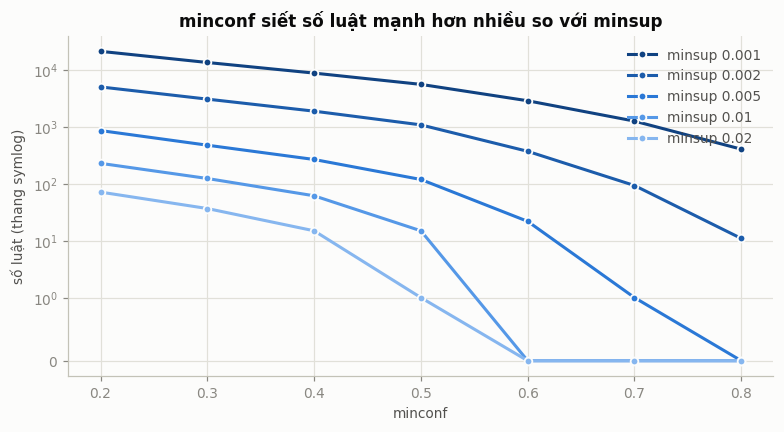

In [27]:
mau = dict(zip(sorted(APP1_MINSUPS, reverse=True), RAMP))   # minsup càng thấp, màu càng đậm

fig, ax = plt.subplots()
for minsup_i, nhom in quet_df.groupby("minsup", sort=True):
    nhom = nhom.sort_values("minconf")
    ax.plot(nhom["minconf"], nhom["số luật"], color=mau[minsup_i], marker="o",
            markeredgecolor=SURFACE, markeredgewidth=1.2, label=f"minsup {minsup_i}")

ax.set_yscale("symlog", linthresh=1)
ax.set_title("minconf siết số luật mạnh hơn nhiều so với minsup")
ax.set_xlabel("minconf")
ax.set_ylabel("số luật (thang symlog)")
ax.legend(title="", loc="upper right", labelcolor=INK_2)
plt.show()

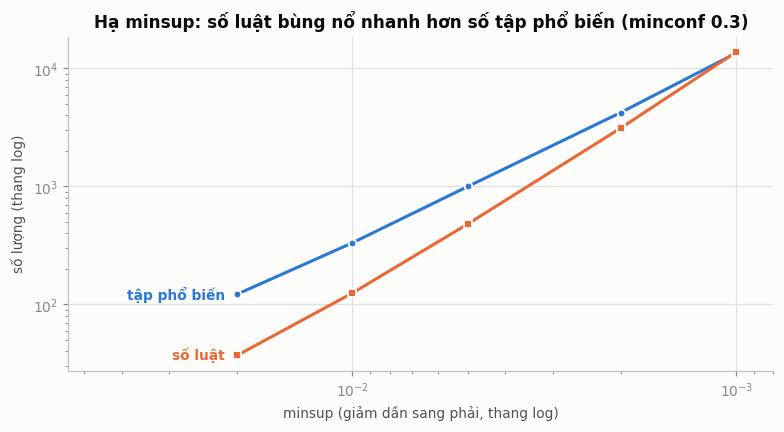

Từ minsup 0.02 xuống 0.001:
  tập phổ biến  122.0 -> 13492.0 (gấp 111 lần)
  số luật        37.0 -> 13770.0 (gấp 372 lần)


In [28]:
mot_minconf = quet_df[quet_df["minconf"] == APP1_MINCONF].sort_values("minsup")

fig, ax = plt.subplots()
for cot, color, marker in (("tập phổ biến", BLUE, "o"), ("số luật", ORANGE, "s")):
    ax.plot(mot_minconf["minsup"], mot_minconf[cot], color=color, marker=marker,
            markeredgecolor=SURFACE, markeredgewidth=1.2)
    # nhãn đặt ở đầu minsup CAO, nơi hai đường còn tách xa nhau
    dau = mot_minconf.iloc[-1]
    ax.annotate(cot, xy=(dau["minsup"], dau[cot]), xytext=(-8, 0),
                textcoords="offset points", color=color, fontweight="bold",
                ha="right", va="center")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(0.055, 0.0008)       # giới hạn giảm dần = trục đảo chiều
ax.set_title(f"Hạ minsup: số luật bùng nổ nhanh hơn số tập phổ biến (minconf {APP1_MINCONF})")
ax.set_xlabel("minsup (giảm dần sang phải, thang log)")
ax.set_ylabel("số lượng (thang log)")
plt.show()

cao, thap = mot_minconf.iloc[-1], mot_minconf.iloc[0]
print(f"Từ minsup {cao['minsup']} xuống {thap['minsup']}:")
print(f"  tập phổ biến {cao['tập phổ biến']:>6} -> {thap['tập phổ biến']:>6} "
      f"(gấp {thap['tập phổ biến'] / cao['tập phổ biến']:.0f} lần)")
print(f"  số luật      {cao['số luật']:>6} -> {thap['số luật']:>6} "
      f"(gấp {thap['số luật'] / cao['số luật']:.0f} lần)")

Hai hình trên nói ba điều:

1. **minconf siết mạnh hơn minsup.** Ở minsup 0,02, nâng minconf từ 0,2 lên 0,5
   là từ 72 luật còn 1 luật, và từ 0,6 trở lên là không còn luật nào — vì giỏ
   trung bình chỉ 4,4 món nên gần như không có món nào "kéo theo" món khác với
   xác suất trên 60%.
2. **Số luật bùng nổ nhanh hơn số tập phổ biến.** Hạ minsup từ 0,02 xuống 0,001
   làm số tập phổ biến gấp khoảng 110 lần, nhưng số luật gấp khoảng 370 lần. Lý
   do nằm ở cấu trúc: một tập phổ biến $k$ item sinh ra $k$ luật khi bên phải chỉ
   một món, mà hạ minsup thì các tập *dài* mới là phần tăng nhanh nhất (ở minsup
   0,001 đã có tập 6 item). Đây chính là mặt "phía luật" của hiện tượng bùng nổ
   tổ hợp mà Chương 2 đo ở phía tập phổ biến.
3. **Lift cao nhất tăng theo khi hạ minsup** — 2,8 ở minsup 0,02 lên 35,7 ở
   0,001. Đừng đọc đó là "tìm được quan hệ mạnh hơn": đó là các cặp món ngách,
   mẫu số $sup(Y)/N$ rất nhỏ nên lift vọt lên, mà cả luật chỉ dựa trên 10 giỏ.
   Mục 3.9 cho thấy chuyện này nghiêm trọng tới mức nào trên CSDL thưa hơn.

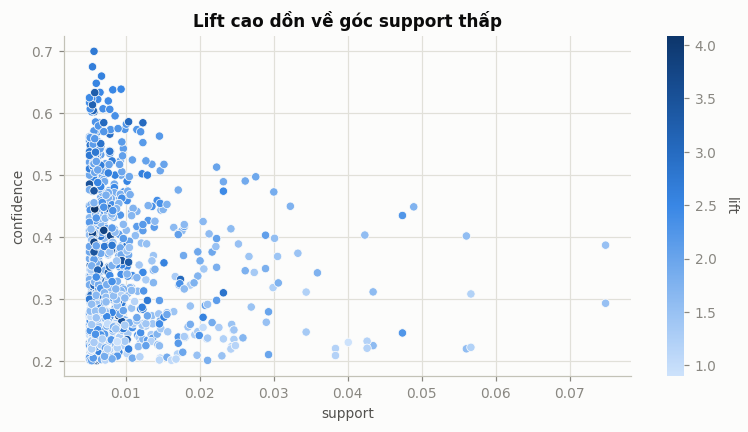

872 luật ở minsup 0,005 và minconf 0,2.
Các điểm đậm nhất (lift cao) dồn hết về mép trái: lift cao gần như luôn đi
với support thấp, nên không bao giờ đọc lift một mình.


In [29]:
# Hình kinh điển của phân tích giỏ hàng: support × confidence, tô màu theo lift.
r_thap = generate_rules(fpgrowth(encoded, to_min_count(0.005, N)), N, 0.2)

fig, ax = plt.subplots()
diem = ax.scatter([rule.support for rule in r_thap],
                  [rule.confidence for rule in r_thap],
                  c=[rule.lift for rule in r_thap], cmap=SEQ,
                  s=30, edgecolor=SURFACE, linewidth=0.5)
thanh = fig.colorbar(diem, ax=ax)
thanh.set_label("lift", color=INK_2, rotation=270, labelpad=14)
thanh.outline.set_visible(False)

ax.set_title("Lift cao dồn về góc support thấp")
ax.set_xlabel("support")
ax.set_ylabel("confidence")
plt.show()

print(f"{len(r_thap)} luật ở minsup 0,005 và minconf 0,2.")
print("Các điểm đậm nhất (lift cao) dồn hết về mép trái: lift cao gần như luôn đi")
print("với support thấp, nên không bao giờ đọc lift một mình.")

### 3.9. Chạy trên CSDL lớn: Retail, và bài học về lift ở dữ liệu thưa

`data/benchmark/retail.txt` — 88.162 giỏ của một nhà bán lẻ Bỉ, 16.470 mặt hàng,
cũng là một trong bốn CSDL benchmark của Chương 2. Item đã bị ẩn danh thành số
nên **không giải thích được ý nghĩa kinh doanh**, nhưng chạy nó trả lời hai câu
hỏi khác: quy trình có làm việc được ở quy mô thật không, và các đo lường cư xử
thế nào khi dữ liệu thưa hơn nữa.

In [30]:
retail_tx, _, _ = load_dataset("retail")
retail_stats = describe(retail_tx)
retail_minsup = APP1_MINSUP_RETAIL
retail_min_count = to_min_count(retail_minsup, len(retail_tx))

start = time.perf_counter()
retail_itemsets = fpgrowth(retail_tx, retail_min_count)
t_retail = time.perf_counter() - start
retail_rules = generate_rules(retail_itemsets, len(retail_tx), APP1_MINCONF)

print(f"minsup {retail_minsup} -> min_count {retail_min_count}")
print(f"{len(retail_itemsets)} tập phổ biến trong {t_retail:.2f}s, "
      f"{len(retail_rules)} luật")

pd.DataFrame([
    {"CSDL": "Groceries", "giao dịch": stats["transactions"],
     "mặt hàng": stats["items"], "giỏ trung bình": round(stats["avg_len"], 2),
     "độ dày": round(stats["density"], 5), "minsup": minsup,
     "min_count": min_count, "tập phổ biến": len(itemsets),
     "số luật": len(rules),
     "lift lớn nhất": round(max(r.lift for r in rules), 1)},
    {"CSDL": "Retail", "giao dịch": retail_stats["transactions"],
     "mặt hàng": retail_stats["items"], "giỏ trung bình": round(retail_stats["avg_len"], 2),
     "độ dày": round(retail_stats["density"], 5), "minsup": retail_minsup,
     "min_count": retail_min_count, "tập phổ biến": len(retail_itemsets),
     "số luật": len(retail_rules),
     "lift lớn nhất": round(max(r.lift for r in retail_rules), 1)},
]).set_index("CSDL")

minsup 0.001 -> min_count 89
7589 tập phổ biến trong 3.83s, 6365 luật


,giao dịch,mặt hàng,giỏ trung bình,độ dày,minsup,min_count,tập phổ biến,số luật,lift lớn nhất
CSDL,,,,,,,,,
Groceries,9835,169,4.41,0.02609,0.010,99,333,125,3.3
Retail,88162,16470,10.31,0.00063,0.001,89,7589,6365,338.3


In [31]:
# Top 5 luật của Retail. Item là số nên chỉ đọc được về mặt định lượng.
pd.DataFrame([{
    "luật": format_rule(rule),
    "giỏ": rule.support_count,
    "support": round(rule.support, 5),
    "confidence": round(rule.confidence, 3),
    "lift": round(rule.lift, 1),
} for rule in sort_rules(retail_rules)[:5]], index=range(1, 6))

,luật,giỏ,support,confidence,lift
1,{697} -> {700},91,0.00103,0.583,338.3
2,{700} -> {697},91,0.00103,0.599,338.3
3,"{796, 1819, 3312} -> {1820}",96,0.00109,0.906,318.1
4,{3403} -> {3536},125,0.00142,0.706,305.2
5,{3536} -> {3403},125,0.00142,0.613,305.2


In [32]:
# Null model trên Retail: kết luận KHÁC hẳn Groceries.
def do_retail(data, nhan):
    its = fpgrowth(data, retail_min_count)
    rs = generate_rules(its, len(retail_tx), APP1_MINCONF)
    lifts = [rule.lift for rule in rs]
    return {"dữ liệu": nhan, "tập phổ biến": len(its), "số luật": len(rs),
            "lift lớn nhất": round(max(lifts), 2) if lifts else 0.0,
            "số luật lift > 1,5": sum(1 for lift in lifts if lift > 1.5)}


hang_retail = [do_retail(retail_tx, "THẬT")]
for i in range(3):          # 3 lần trộn là đủ để thấy, Retail chạy chậm hơn
    hang_retail.append(do_retail(shuffle_keep_marginals(retail_tx, SEED + i),
                                 f"trộn, seed {SEED + i}"))

pd.DataFrame(hang_retail)

,dữ liệu,tập phổ biến,số luật,lift lớn nhất,"số luật lift > 1,5"
0,THẬT,7589,6365,338.34,1506
1,"trộn, seed 42",6326,4144,2.81,2126
2,"trộn, seed 43",6369,4177,2.68,2175
3,"trộn, seed 44",6341,4174,2.63,2159


#### Hai bài học, và một chỗ phải thú nhận

**Bài học 1 — lift không ổn định khi support thấp.** Retail cho lift cao nhất tới
**338**, gấp hơn 100 lần mức 3,3 của Groceries. Đó **không** phải vì quan hệ mạnh
hơn, mà vì mẫu số $sup(Y)/N$ rất nhỏ: cả luật chỉ dựa trên 91 giỏ trong 88.162
giỏ. Ước lượng dựa trên 91 quan sát có phương sai lớn, và hạ minsup thêm thì lift
cao nhất lại tăng. Kết luận phương pháp: **ở CSDL thưa, không xếp hạng bằng lift
trần.** Phải kèm ngưỡng support tuyệt đối tối thiểu, hoặc chuyển sang leverage —
đo lường này tự động phạt các luật support thấp.

**Bài học 2 — null model phải đọc theo đúng thống kê.** Trên Groceries, dữ liệu
trộn sụp ở cả ba thống kê. Trên Retail thì **không**: số luật chỉ giảm khoảng 1,5
lần, và số luật có lift > 1,5 của dữ liệu **trộn còn nhiều hơn** dữ liệu thật.
Chỉ phần đỉnh của phân bố lift mới tách ra rõ (338 so với khoảng 2,7). Lý do:
Retail có độ dày 0,0006 — khi support nền của mỗi món đã cực bé thì hai món ngẫu
nhiên rơi vào cùng giỏ cũng đủ cho lift vượt 1,5. Nghĩa là **ngưỡng "lift > 1,5"
không chứng minh được gì trên CSDL thưa**; đó là một kết quả âm, và nó đáng báo
cáo đúng như nó là.

**Chỗ phải thú nhận:** vì item Retail đã ẩn danh, không ai kiểm được luật
`{697} -> {700}` có hợp lý hay không. Số liệu vẫn đúng, nhưng giá trị sử dụng
bằng không. Bài học thực tế: **giá trị của luật kết hợp phụ thuộc vào việc có từ
điển item hay không, chứ không phụ thuộc thuật toán.** Khi triển khai thật, việc
giữ được bảng mã món là phần quan trọng ngang với việc chạy được thuật toán.

### 3.10. Kết luận

**Đã làm được gì.** Toàn bộ quy trình phân tích giỏ hàng chạy trên cài đặt
FP-Growth của nhóm: đọc dữ liệu thật, biến đổi thành giao dịch, khai thác tập phổ
biến, sinh luật kết hợp với bốn đo lường, và diễn giải. Trên Groceries (9.835
giỏ, 169 mặt hàng) ở minsup 0,01 và minconf 0,3 ra 333 tập phổ biến và 125 luật
trong dưới 0,1 giây. Quy trình chạy lại nguyên vẹn trên Retail (88.162 giỏ,
16.470 mặt hàng) trong khoảng 3 giây.

**Bốn mốc kiểm chứng** — đối chiếu **kết quả số** với các giá trị đã công bố của
bộ Groceries, không đọc và không sao chép code của bất kỳ cài đặt nào:

| Mốc | Nhóm tính được | Giá trị công bố |
|---|---|---|
| support(`whole milk`) | 2513 / 9835 = 0,25552 | 0,25552 |
| `{other vegetables, yogurt} -> {whole milk}` | sup 0,02227 · conf 0,51288 · lift 2,00723 | 0,02226 · 0,5128 · 2,0072 |
| số luật tại minsup 0,01 và minconf 0,5 | 15 | 15 |
| số luật tại minsup 0,001 và minconf 0,8 | 410 | 410 |

Khớp ở cả hai đầu của dải tham số (333 tập phổ biến và 13.492 tập phổ biến) thì
khó mà đúng do may.

**Ba đề xuất hành động cho cửa hàng**, theo thứ tự hiệu ứng tuyệt đối
(`leverage`), không theo lift:

1. Gộp quầy rau củ và trái cây thành một khu "nguyên liệu nấu ăn" — nhóm luật này
   chiếm 7 trong 10 luật mạnh nhất, và luật
   `{other vegetables, whole milk} -> {root vegetables}` một mình đã phủ 228 giỏ.
2. Đặt kệ củ tại quầy thịt bò — luật `{beef} -> {root vegetables}` là luật dễ
   dùng nhất vì chỉ cần một món bên trái.
3. Chuyển sữa chua về cạnh quầy sữa, bỏ khỏi khu tráng miệng.

**Bốn kết luận về phương pháp**, là phần nhóm thấy đáng giá nhất:

1. **Bốn đo lường, bốn câu hỏi khác nhau, không thay thế được nhau.** Xếp theo
   confidence thì top 5 bị `whole milk` chiếm chỗ và ta chỉ phát hiện lại "sữa
   bán chạy". Xếp theo lift trần thì chọn phải các cặp ngách chỉ dựa trên vài
   chục giỏ. `leverage` là đo lường ra quyết định được, vì nó phạt support thấp.
2. **Null model là bước nên có.** Trộn món giữa các giỏ nhưng giữ nguyên độ bán
   chạy cho thấy dữ liệu thật sinh ra gấp hơn 20 lần số luật lift mạnh — bằng
   chứng các mẫu là thật. Chi phí gần như bằng không vì dùng lại chính `fpgrowth`.
3. **Nhưng kết luận của null model phụ thuộc độ thưa của dữ liệu.** Trên Retail,
   ngưỡng "lift > 1,5" mất hoàn toàn tác dụng — dữ liệu trộn còn vượt ngưỡng
   nhiều hơn dữ liệu thật. Phải chọn thống kê so sánh theo từng CSDL, và đây là
   lý do `compare_real_vs_shuffled` trong `scripts/app1_curves.py` cố ý in cả ba
   tỉ số thay vì viết sẵn một câu kết luận.
4. **Số luật bùng nổ nhanh hơn số tập phổ biến** (370 lần so với 110 lần khi hạ
   minsup 20 lần). Nối tiếp phần bùng nổ tổ hợp mà Chương 2 đo ở phía tập phổ
   biến, và là lý do phải lọc luật chứ không chỉ lọc tập phổ biến.

**Hạn chế, nói thẳng để trả lời vấn đáp.** (a) `max_consequent=1` nên không sinh
luật có nhiều món bên phải; trên Groceries ở minsup 0,01 việc này chỉ bỏ sót 3
luật (231 so với 234 ở minconf 0,2), nhưng ở minsup 0,001 thì bỏ sót khoảng 14%
(21.633 so với 25.022). (b) Null model có thể đặt hai lượt của cùng một món vào một giỏ, nên dữ liệu
trộn hơi loãng hơn thật; lệch này làm null model dễ thắng hơn nên không thổi
phồng kết luận. (c) Chưa kiểm định thống kê theo nghĩa p-value, chỉ so với trung
vị của 5 lần trộn. (d) Dữ liệu Groceries không có giá và số lượng, nên không ước
lượng được doanh thu của một combo, chỉ ước lượng được số giỏ.

**Tái lập.** Mọi ngưỡng nằm trong `src/config.py`, `SEED = 42` ở mọi chỗ có ngẫu
nhiên. Chạy lại ngoài notebook:

```bash
python -m scripts.app1_basket --minsup 0.01 --minconf 0.3 --top 10
python -m scripts.app1_basket --minsup 0.01 --minconf 0.5     # phải ra đúng 15 luật
python -m scripts.app1_curves --dataset groceries
python -m scripts.app1_curves --dataset retail
python -m pytest tests/test_rules.py tests/test_basket.py -v
```

#### Tài liệu tham khảo

1. J. Han, J. Pei, Y. Yin, R. Mao. *Mining Frequent Patterns without Candidate
   Generation: A Frequent-Pattern Tree Approach.* Data Mining and Knowledge
   Discovery, 8(1):53–87, 2004. — thuật toán FP-Growth mà nhóm cài đặt lại.
2. R. Agrawal, R. Srikant. *Fast Algorithms for Mining Association Rules.*
   VLDB 1994. — định nghĩa luật kết hợp, support và confidence.
3. S. Brin, R. Motwani, J. D. Ullman, S. Tsur. *Dynamic Itemset Counting and
   Implication Rules for Market Basket Data.* SIGMOD 1997. — lift (interest).
4. M. Hahsler, B. Grün, K. Hornik. *arules — A Computational Environment for
   Mining Association Rules and Frequent Item Sets.* Journal of Statistical
   Software, 14(15), 2005. — **nguồn dữ liệu Groceries và các giá trị số dùng để
   kiểm chứng**, không phải nguồn mã nguồn.
5. P.-N. Tan, M. Steinbach, V. Kumar. *Introduction to Data Mining.* — chương về
   interestingness measures (lift, leverage, conviction) và về mô hình đối chứng.

## 4. Ứng dụng 2: Khai thác mẫu trong chuỗi DNA (splice junction)

Đề cho hướng **phân tích dữ liệu sinh học**: mã hoá chuỗi gen thành giao dịch, chạy
FP-Growth của nhóm và **thảo luận ý nghĩa sinh học** của các pattern tìm được.

**Câu hỏi đặt ra:** chỉ nhìn vào chuỗi DNA, không cho trước kiến thức sinh học nào,
FP-Growth có tự tìm ra các "tín hiệu" mà tế bào dùng để nhận biết chỗ cắt intron hay không?

| Mục | Nội dung |
|---|---|
| 4.1 | Bối cảnh sinh học: exon, intron, splicing, donor, acceptor |
| 4.2 | Dữ liệu và cách biến chuỗi DNA thành giao dịch |
| 4.3 | Chọn minsup |
| 4.4 | Top itemset và dựng lại *consensus sequence* |
| 4.5 | Ngoại lệ của quy tắc GT–AG |
| 4.6 | Emerging pattern: EI, IE so với N |
| 4.7 | Hạn chế: polypyrimidine tract bị "tàng hình" |
| 4.8 | Mở rộng: thêm item lớp nucleotide (Y/R) |
| 4.9 | Kết luận |

### 4.1. Bối cảnh sinh học

**Exon, intron và splicing.** Gen của sinh vật nhân thực không liền một khối mà gồm các
đoạn **exon** (được giữ lại để dịch thành protein) xen kẽ các đoạn **intron** (bị cắt
bỏ). Quá trình cắt intron và nối các exon lại gọi là **splicing**, do một phức hợp gọi là
*spliceosome* thực hiện. Cắt lệch dù chỉ một nucleotide là khung đọc bị dịch và protein
phía sau sai hoàn toàn, nên tế bào cần các "dấu hiệu" rất rõ ở hai đầu intron.

```
      exon            intron                              exon
 ...C A G | G T A A G T ......... T T C T C T T T C A G | G ...
          ^                                             ^
     donor  (EI)                                  acceptor (IE)
  ranh giới exon→intron                     ranh giới intron→exon
```

Ba nhãn trong dữ liệu:

| Nhãn | Ý nghĩa | Vai trò trong phân tích |
|---|---|---|
| **EI** | chuỗi có ranh giới exon→intron ở giữa (**donor**) | nhóm cần tìm tín hiệu |
| **IE** | chuỗi có ranh giới intron→exon ở giữa (**acceptor**) | nhóm cần tìm tín hiệu |
| **N** | chuỗi không chứa ranh giới nào | **nhóm đối chứng** |

**Quy tắc GT–AG.** Gần như mọi intron **bắt đầu bằng GT** và **kết thúc bằng AG**. Đây là
tín hiệu mạnh nhất mà ta kỳ vọng FP-Growth tìm ra.

**Consensus sequence và mã IUPAC.** *Consensus sequence* (trình tự đồng thuận) là chuỗi
ghép từ nucleotide phổ biến nhất ở từng vị trí. Khi một vị trí thường là một trong hai
nucleotide, sinh học dùng mã **IUPAC**:

| Mã | Nghĩa | Mã | Nghĩa |
|---|---|---|---|
| R | A hoặc G (*purine*) | Y | C hoặc T (*pyrimidine*) |
| M | A hoặc C | K | G hoặc T |
| N | bất kỳ | | |

Sách sinh học phân tử ghi consensus của donor là **`MAG|GTRAGT`** và của acceptor là
**`(Y)n NCAG|G`**, trong đó `(Y)n` là **polypyrimidine tract**: một đoạn 10–20 nucleotide
giàu C và T ngay trước `AG`, nơi các protein của spliceosome bám vào để nhận ra acceptor.

**Kỳ vọng nếu FP-Growth hoạt động tốt:** (1) tìm ra `GT` ở donor, (2) tìm ra `AG` ở
acceptor, (3) không thấy gì nổi bật ở nhóm N.

### 4.2. Dữ liệu và biến đổi thành giao dịch

**Dữ liệu:** UCI *Molecular Biology (Splice-junction Gene Sequences)*, gồm 3.190 chuỗi DNA
của linh trưởng, mỗi chuỗi dài 60 nucleotide, ranh giới (nếu có) nằm **chính giữa**.

**Biến chuỗi thành giao dịch:** mỗi chuỗi là một giao dịch, mỗi item có dạng
`P<vị trí>=<nucleotide>`, vị trí đánh từ −30 đến +30 so với ranh giới (không có vị trí 0).
Ví dụ `P+1=G` là "G ở ngay sau ranh giới", `P-1=G` là "G ở ngay trước ranh giới".

In [33]:
from src.app2_bio import read_splice, to_transaction, load_groups

DATA_PATH = "data/app2/splice.data"
rows = read_splice(DATA_PATH)
label, seq = rows[0]
t = to_transaction(seq)
print(f"Mẫu đầu tiên ({label}): {seq}")
print(f"Giao dịch: {len(t)} item, quanh ranh giới: {t[27:33]}")

groups, code = load_groups(DATA_PATH)
print(f"{len(code)} item khác nhau | " + ", ".join(f"{k}: {len(v)} mẫu" for k, v in groups.items()))

Mẫu đầu tiên (EI): CCAGCTGCATCACAGGAGGCCAGCGAGCAGGTCTGTTCCAAGGGCCTTCGAGCCAGTCTG
Giao dịch: 60 item, quanh ranh giới: ['P-3=C', 'P-2=A', 'P-1=G', 'P+1=G', 'P+2=T', 'P+3=C']
240 item khác nhau | EI: 767 mẫu, IE: 768 mẫu, N: 1655 mẫu


In [34]:
from collections import Counter

# Ký tự không chắc chắn (mã IUPAC) trong dữ liệu gốc
la = Counter(ch for _, s in rows for ch in s if ch not in "ACGT")
so_mau = sum(1 for _, s in rows if any(ch not in "ACGT" for ch in s))
print("Ký tự không phải A/C/G/T:", dict(la))
print(f"Số chuỗi có ít nhất một ký tự như vậy: {so_mau}/{len(rows)}")

Ký tự không phải A/C/G/T: {'N': 56, 'D': 2, 'R': 1, 'S': 1}
Số chuỗi có ít nhất một ký tự như vậy: 15/3190


**Nhận xét.**

- **Vì sao phải ghép vị trí vào item?** Nếu item chỉ là `A`, `C`, `G`, `T` thì chuỗi
  dài 60 nào cũng chứa đủ cả 4 chữ, mọi giao dịch giống hệt nhau và không khai thác được
  gì. Trong sinh học, *vị trí* mới quyết định ý nghĩa: `G` ở +1 là tín hiệu donor, còn `G`
  ở +20 chẳng nói lên điều gì.
- **240 item** = 60 vị trí × 4 nucleotide. Mỗi giao dịch có đúng 60 item (một item cho mỗi
  vị trí), trừ các chuỗi có ký tự không chắc chắn.
- Chỉ **15/3.190 chuỗi** có ký tự không chắc chắn (`N` = chưa xác định, `D`, `R`, `S` là
  mã IUPAC nhiều khả năng). Các ký tự này bị **bỏ qua** thay vì đoán, nên giao dịch đó chỉ
  thiếu vài item và không ảnh hưởng đáng kể tới support.
- Cả 3 nhóm dùng **chung một bảng mã**, nên cùng một số luôn là cùng một item ở mọi nhóm.
  Đây là điều kiện bắt buộc để so sánh support giữa các nhóm ở mục 4.6.

### 4.3. Chọn minsup

Mỗi vị trí có 4 khả năng, nên với DNA "ngẫu nhiên" mỗi item có support khoảng **25%**. Đây
là **mức nền**: một item chỉ đáng chú ý khi vượt xa 25%. Chạy FP-Growth riêng từng nhóm ở
nhiều mức minsup:

In [35]:
import pandas as pd
from src.algorithm.fpgrowth import fpgrowth
from src.config import to_min_count

table = {}
for minsup in [0.3, 0.5, 0.7]:
    table[minsup] = {label: len(fpgrowth(data, to_min_count(minsup, len(data))))
                     for label, data in groups.items()}
pd.DataFrame(table).T.rename_axis("minsup")

,EI,IE,N
minsup,,,
0.3,280,331,0
0.5,35,7,0
0.7,15,7,0


In [36]:
from src.utils import invert_code

name_of = invert_code(code)

# Item đơn mạnh nhất của mỗi nhóm: support cao nhất của một item là bao nhiêu?
for label, data in groups.items():
    dem = Counter(item for t in data for item in t)
    item, sup = dem.most_common(1)[0]
    print(f"{label:>2}: item mạnh nhất {name_of[item]:<7} support {sup / len(data):.1%}")

EI: item mạnh nhất P+1=G   support 99.7%
IE: item mạnh nhất P-1=G   support 99.7%
 N: item mạnh nhất P+19=G  support 28.9%


**Nhận xét.**

- Nhóm **N** có 0 itemset ở cả ba mức. Nhưng phải đọc đúng con số này: item mạnh nhất của N
  chỉ đạt **28,9%**, sát mức nền 25%. Vậy ở minsup 0,3 thì DNA ngẫu nhiên nào cũng ra 0
  itemset, con số 0 **tự nó không phải bằng chứng**. Bằng chứng thật là sự tương phản:
  EI và IE có những vị trí đạt **99,7%**, tức gần như mọi mẫu đều giống nhau ở đó, còn N
  thì không có vị trí nào như vậy. Nói theo sinh học: EI và IE có các vị trí **được bảo
  tồn** (*conserved*), N thì không.
- Ở minsup **0,3** (chỉ cao hơn mức nền một chút), EI và IE cho hàng trăm itemset, phần lớn
  là tổ hợp của các item chỉ hơi vượt nền, khó diễn giải.
- Chọn minsup **0,5** (gấp đôi mức nền): EI còn 35, IE còn 7 itemset, đều là tín hiệu
  mạnh và đọc được bằng mắt. Mức 0,7 không bớt đi itemset nào của IE, chứng tỏ 7 itemset
  của IE đều rất mạnh.

### 4.4. Top itemset và dựng lại consensus sequence

In [37]:
from src.utils import decode

for label in ["EI", "IE"]:
    data = groups[label]
    named = decode(fpgrowth(data, to_min_count(0.5, len(data))), code)
    top = sorted(named.items(), key=lambda x: x[1], reverse=True)[:7]
    print(f"\nTop của {label}:")
    for itemset, sup in top:
        print(f"  {sup / len(data):6.1%}  {itemset}")


Top của EI:
   99.7%  ('P+1=G',)
   99.0%  ('P+2=T',)
   99.0%  ('P+1=G', 'P+2=T')
   85.7%  ('P+5=G',)
   85.5%  ('P+1=G', 'P+5=G')
   85.0%  ('P+2=T', 'P+5=G')
   85.0%  ('P+1=G', 'P+2=T', 'P+5=G')

Top của IE:
   99.7%  ('P-1=G',)
   99.6%  ('P-2=A',)
   99.5%  ('P-1=G', 'P-2=A')
   78.9%  ('P-3=C',)
   78.9%  ('P-1=G', 'P-3=C')
   78.8%  ('P-2=A', 'P-3=C')
   78.8%  ('P-1=G', 'P-2=A', 'P-3=C')


FP-Growth tìm ra đúng **GT** (`P+1=G, P+2=T`, 99,0%) ở donor và **AG** (`P-2=A, P-1=G`,
99,5%) ở acceptor. Để so với consensus trong sách, ta xem tần suất từng nucleotide tại các
vị trí quanh ranh giới, rồi ghép thành consensus theo quy tắc:

- nucleotide mạnh nhất ≥ 50%: ghi chữ đó (in hoa);
- hai nucleotide mạnh nhất cộng lại ≥ 70%: ghi mã IUPAC của cặp đó (R, Y, M, K…);
- nucleotide mạnh nhất ≥ 40%: ghi chữ thường (ưu tiên yếu);
- còn lại: `N` (không có ưu tiên).

In [38]:
from src.app2_bio import position_name

IUPAC = {"AG": "R", "CT": "Y", "AC": "M", "GT": "K", "CG": "S", "AT": "W"}

def bang_tan_suat(seqs, start, end):
    """Tỉ lệ A/C/G/T tại từng chỉ số start..end-1 (chỉ số Python 0..59)."""
    dong = []
    for i in range(start, end):
        dem = Counter(s[i] for s in seqs)
        dong.append({"vị trí": position_name(i),
                     **{b: round(dem[b] / len(seqs), 2) for b in "ACGT"}})
    return pd.DataFrame(dong).set_index("vị trí")

def consensus(bang):
    """Ghép consensus theo 4 quy tắc ở trên; dấu | là ranh giới."""
    kq = ""
    for vi_tri, dong in bang.iterrows():
        top = dong.sort_values(ascending=False)
        b1, b2 = top.index[0], top.index[1]
        if top.iloc[0] >= 0.5:
            chu = b1
        elif top.iloc[0] + top.iloc[1] >= 0.7:
            chu = IUPAC["".join(sorted(b1 + b2))]
        elif top.iloc[0] >= 0.4:
            chu = b1.lower()
        else:
            chu = "N"
        if vi_tri == "+1":
            kq += "|"
        kq += chu
    return kq

seqs = {lab: [s for l, s in rows if l == lab] for lab in ["EI", "IE", "N"]}

bang_ei = bang_tan_suat(seqs["EI"], 25, 37)     # vị trí -5 .. +7
display(bang_ei.T)
print("Consensus EI:", consensus(bang_ei))

vị trí,-5,-4,-3,-2,-1,+1,+2,+3,+4,+5,+6,+7
A,0.25,0.22,0.32,0.58,0.08,0.0,0.00,0.49,0.72,0.05,0.16,0.24
C,0.24,0.29,0.38,0.14,0.03,0.0,0.01,0.02,0.09,0.05,0.16,0.21
G,0.24,0.32,0.17,0.15,0.81,1.0,0.00,0.46,0.13,0.86,0.22,0.39
T,0.26,0.18,0.13,0.13,0.07,0.0,0.99,0.02,0.06,0.05,0.45,0.16


Consensus EI: NNMAG|GTRAGtN


In [39]:
pd.set_option("display.max_columns", 30)        # hiện đủ 22 cột, không bị "..."
bang_ie = bang_tan_suat(seqs["IE"], 10, 32)     # vị trí -20 .. +2
display(bang_ie.T)
print("Consensus IE:", consensus(bang_ie))
print("Consensus N :", consensus(bang_tan_suat(seqs["N"], 25, 35)))

vị trí,-20,-19,-18,-17,-16,-15,-14,-13,-12,-11,-10,-9,-8,-7,-6,-5,-4,-3,-2,-1,+1,+2
A,0.18,0.16,0.14,0.15,0.13,0.11,0.10,0.08,0.07,0.07,0.09,0.10,0.05,0.08,0.05,0.07,0.24,0.02,1.0,0.0,0.28,0.23
C,0.28,0.33,0.37,0.38,0.39,0.38,0.35,0.35,0.37,0.36,0.37,0.36,0.42,0.45,0.46,0.40,0.31,0.79,0.0,0.0,0.14,0.21
G,0.20,0.18,0.16,0.15,0.15,0.12,0.13,0.13,0.11,0.11,0.09,0.11,0.11,0.07,0.06,0.07,0.25,0.01,0.0,1.0,0.48,0.23
T,0.33,0.33,0.33,0.32,0.33,0.39,0.42,0.44,0.44,0.46,0.45,0.43,0.41,0.39,0.43,0.46,0.20,0.18,0.0,0.0,0.10,0.32


Consensus IE: NNYYYYYYYYYYYYYYNCAG|RN
Consensus N : NNNNN|NNNNN


Đã lưu docs/figures/app2_profile.png


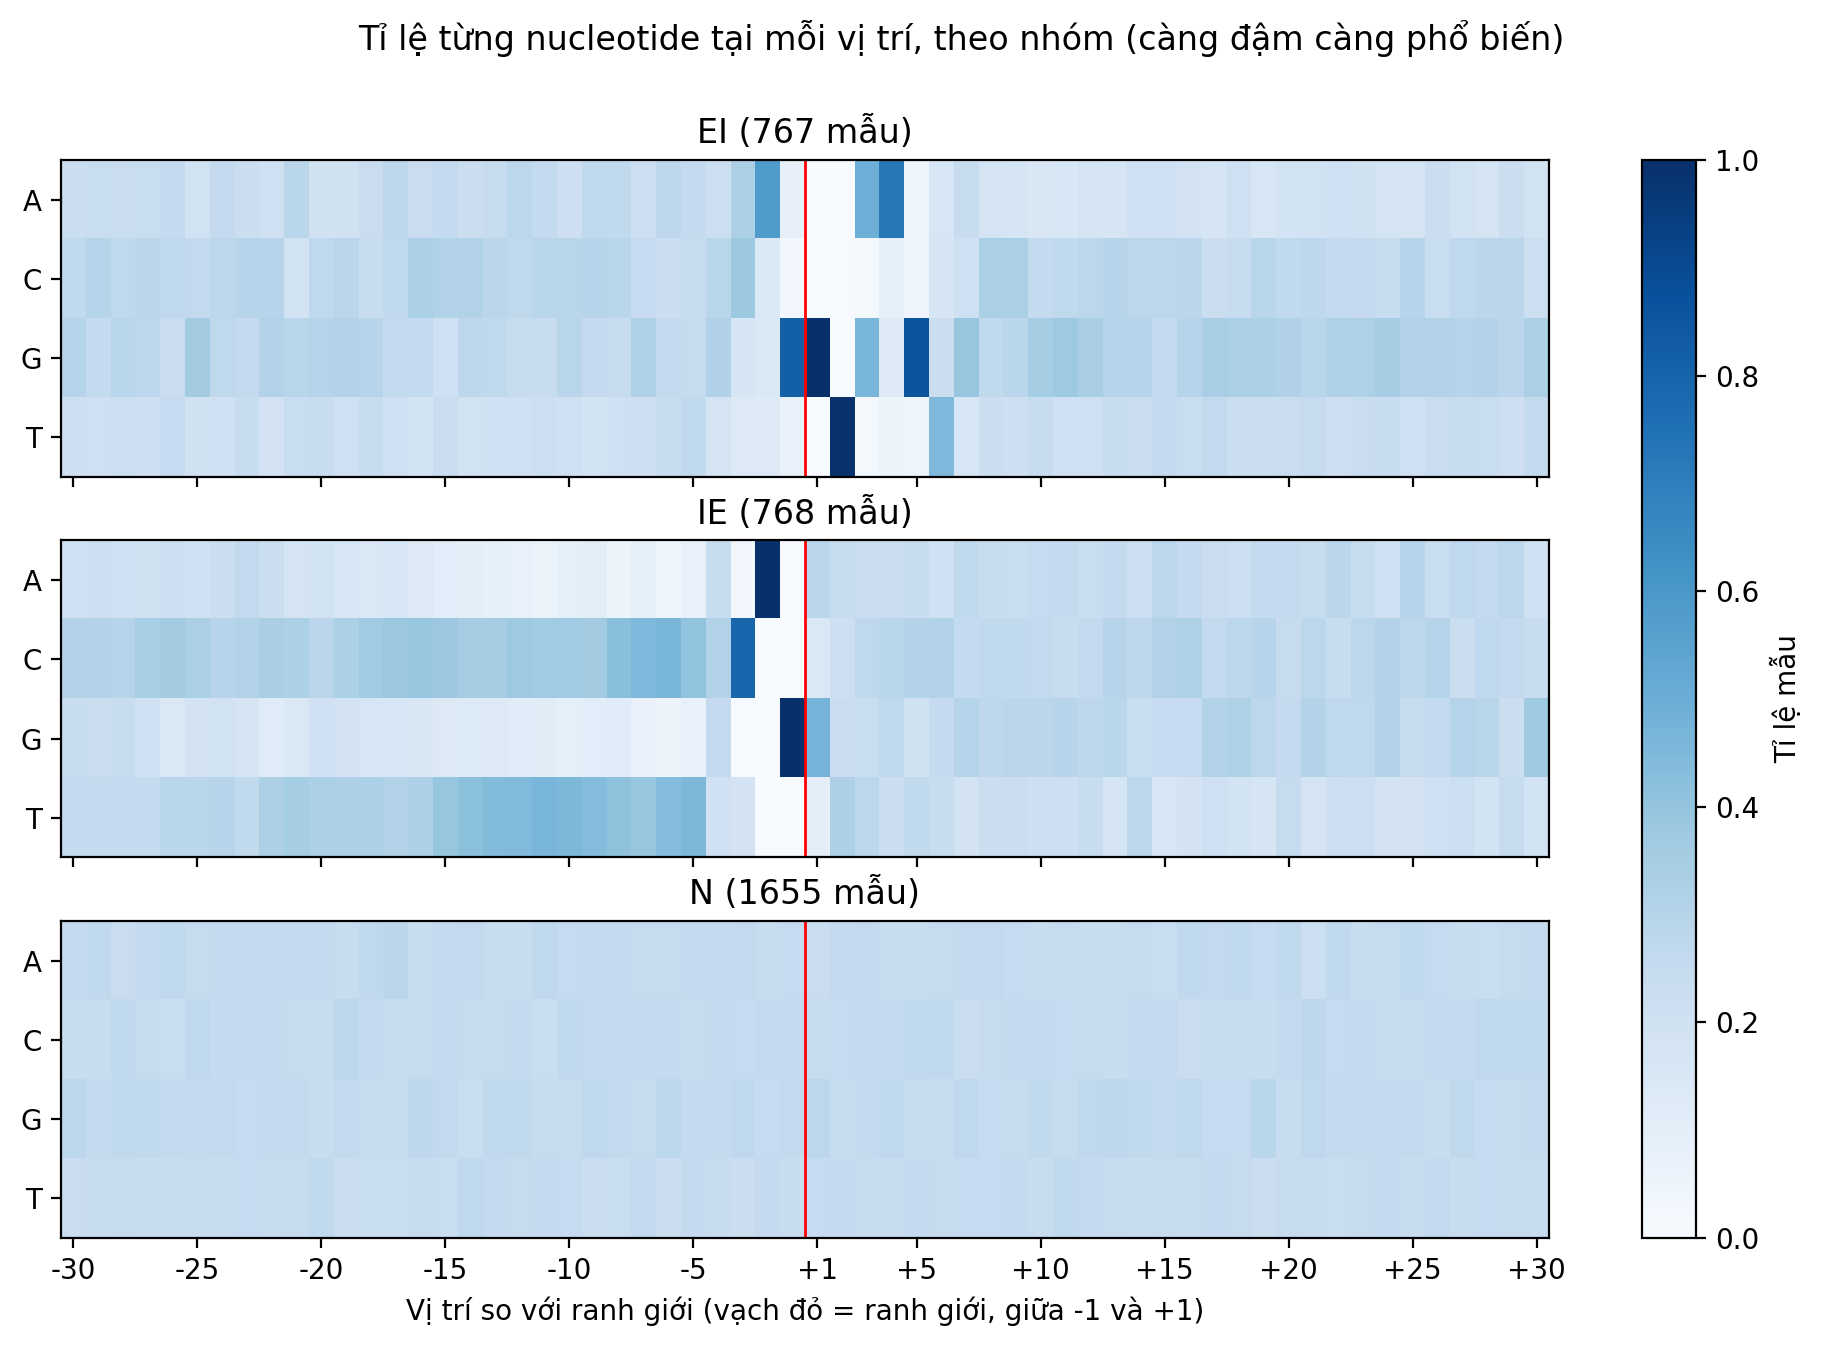

In [40]:
from IPython.display import Image
from scripts.app2_plot import plot_profile

os.makedirs("docs/figures", exist_ok=True)
plot_profile(rows)
display(Image("docs/figures/app2_profile.png", width=900))

**Nhận xét.**

- **Donor (EI):** bỏ hai chữ `N` ở hai đầu, consensus dựng từ dữ liệu là `MAG|GTRAGt`, khớp gần như từng chữ với
  `MAG|GTRAGT` trong sách. Vị trí +6 ra chữ thường (`t`, 45%) vì T chỉ là ưu tiên yếu ở vị
  trí này. Trên heatmap, cột +1 và +2 gần như đậm tuyệt đối, các cột +3 đến +5 và −1 đến −3
  đậm vừa: tín hiệu donor kéo dài khoảng 9 nucleotide quanh ranh giới chứ không chỉ 2.
- **Vị trí +3 là R**: A 49%, G 46%. Đây là ví dụ đầu tiên cho thấy *một tín hiệu sinh học
  có thể là "một trong hai chữ"*. Tách riêng thì không chữ nào đạt minsup 0,5, nên +3 vắng
  mặt trong mọi itemset ở trên. Ta quay lại vấn đề này ở 4.7.
- **Acceptor (IE):** consensus là `YYYYYYYYYYYYYYNCAG|R`, tức đúng `(Y)n NCAG|G` của sách:
  14 vị trí liên tiếp là Y (polypyrimidine tract), rồi `N` ở −4, rồi `CAG`. Riêng +1 ra `R`
  (G 48%, A 28%), sách ghi G.
- **Nhóm N:** consensus `NNNNN|NNNNN`, không vị trí nào có ưu tiên. Đúng vai trò đối chứng.
- **Itemset cho thêm gì so với consensus?** Consensus chỉ nói về *từng vị trí riêng lẻ*;
  itemset nói các item **xuất hiện cùng nhau trong cùng một mẫu**. Ví dụ
  `{P+1=G, P+2=T, P+5=G}` có trong 85,0% mẫu EI, gần bằng tích các support riêng
  (99,7% × 99,0% × 85,7% ≈ 84,6%). Nghĩa là trong nhóm EI các vị trí này gần như độc lập
  với nhau. Giá trị thật của itemset hiện ra khi **so với nhóm N** (mục 4.6).

### 4.5. Ngoại lệ của quy tắc GT–AG

GT có trong 99,0% mẫu EI, vậy 1% còn lại là gì? Ngoại lệ là chỗ thú vị để kiểm tra xem
dữ liệu có khớp với hiểu biết sinh học đã công bố hay không.

In [41]:
from scripts.app2_check import show_exceptions
from src.app2_bio import read_splice_with_name

rows_named = read_splice_with_name(DATA_PATH)
show_exceptions(rows_named, "EI", 30, "GT")    # donor: GT ở +1,+2 = seq[30:32]
show_exceptions(rows_named, "IE", 28, "AG")    # acceptor: AG ở -2,-1 = seq[28:30]


EI: 8/767 mẫu không có GT
  thay vào đó là: Counter({'GC': 4, 'NN': 1, 'GG': 1, 'GA': 1, 'CA': 1})
  HUMALPI1-DONOR-42         NNNNN|NNNNN
  HUMAPRTA-DONOR-881        CGCAG|GCGAG
  HUMFVII-DONOR-70          TGCAG|GCGGG
  HUMINCPPS-DONOR-940       GCAGG|GGCCA
  HUMINCPPS-DONOR-2825      TGAGG|GAGTA
  HUMKER18-DONOR-4285       AAGAG|GCAAG
  HUMMYC3L-DONOR-2594       CTCTA|CAACG
  HUMTHB-DONOR-10723        TGCTG|GCAAG

IE: 4/768 mẫu không có AG
  thay vào đó là: Counter({'AC': 1, 'TG': 1, 'GG': 1, 'CA': 1})
  HUMAK1-ACCEPTOR-3918      CTTAC|AGAGC
  HUMAK1-ACCEPTOR-10488     CGCTG|AGGGC
  HUMALPI1-ACCEPTOR-124     CCTGG|CCAGC
  HUMINCPPS-ACCEPTOR-2712   ATACA|TGTAT


In [42]:
# Với mẫu ngoại lệ: GT/AG có nằm lệch đi vài vị trí so với ranh giới đã chú thích không?
def tim_lech(seq, start, expected, ban_kinh=3):
    """Trả về các độ lệch d (-3..+3, khác 0) mà seq[start+d : start+d+2] == expected."""
    return [d for d in range(-ban_kinh, ban_kinh + 1)
            if d != 0 and seq[start + d:start + d + 2] == expected]

for label, start, expected in [("EI", 30, "GT"), ("IE", 28, "AG")]:
    print(f"\n{label}: tìm {expected} lệch khỏi ranh giới")
    for lab, name, s in rows_named:
        if lab == label and s[start:start + 2] != expected:
            print(f"  {name:<25} {s[start:start + 2]}  lệch: {tim_lech(s, start, expected)}")


EI: tìm GT lệch khỏi ranh giới
  HUMALPI1-DONOR-42         NN  lệch: []
  HUMAPRTA-DONOR-881        GC  lệch: []
  HUMFVII-DONOR-70          GC  lệch: []
  HUMINCPPS-DONOR-940       GG  lệch: []
  HUMINCPPS-DONOR-2825      GA  lệch: [2]
  HUMKER18-DONOR-4285       GC  lệch: []
  HUMMYC3L-DONOR-2594       CA  lệch: []
  HUMTHB-DONOR-10723        GC  lệch: []

IE: tìm AG lệch khỏi ranh giới
  HUMAK1-ACCEPTOR-3918      AC  lệch: [2]
  HUMAK1-ACCEPTOR-10488     TG  lệch: [2]
  HUMALPI1-ACCEPTOR-124     GG  lệch: []
  HUMINCPPS-ACCEPTOR-2712   CA  lệch: []


**Nhận xét.**

- **Donor:** 759/767 mẫu (99,0%) có GT. Trong 8 ngoại lệ, **4 mẫu là GC** (0,52%). Intron
  **GC–AG** là một loại intron có thật trong sinh học, không phải lỗi. Burset và cộng sự
  (2000) phân tích 22.489 cặp splice site của động vật có vú đã được kiểm chứng bằng EST và
  thấy **98,71% là GT–AG, 0,56% là GC–AG**. Tỉ lệ của dữ liệu này (99,0% và 0,52%) **khớp
  rất sát** với số liệu công bố.
- **Acceptor:** 764/768 mẫu (99,5%) có AG, chỉ 4 ngoại lệ, mỗi loại một mẫu.
- **Một số ngoại lệ có dấu hiệu lỗi chú thích.** Ô trên cho thấy **3 mẫu** có GT hoặc AG
  nằm **lệch đúng 2 vị trí** so với ranh giới ghi trong dữ liệu: `HUMINCPPS-DONOR-2825`
  (GT ở +3,+4), `HUMAK1-ACCEPTOR-3918` và `HUMAK1-ACCEPTOR-10488` (AG ở +1,+2 thay vì
  −2,−1). Nếu dời ranh giới đi 2 vị trí thì cả ba trở lại đúng quy tắc GT–AG.
  Burset (2000) cũng ghi nhận nhiều splice site "không chuẩn" thực ra chỉ là ranh giới bị
  chú thích lệch, hoặc là lỗi giải trình tự. Mẫu `HUMALPI1-DONOR-42` toàn `N` là dữ liệu
  thiếu.
- **Ý nghĩa với FP-Growth:** minsup là ngưỡng *tương đối*, nên vài mẫu ngoại lệ hay lỗi
  không làm mất pattern GT–AG. Đây là ưu điểm của khai thác tập phổ biến trên dữ liệu thật
  có nhiễu: nó tìm *xu hướng chung* và chịu được vài mẫu sai.

### 4.6. Emerging pattern: EI, IE so với N

**Định nghĩa.** *Emerging pattern* (Dong và Li, 1999) là itemset có support **tăng mạnh**
từ nhóm này sang nhóm khác. Độ tăng đo bằng **growth rate**:

$$\text{growth}(X) = \frac{\text{sup}_{EI}(X)}{\text{sup}_{N}(X)}$$

với $\text{sup}_{EI}(X)$ và $\text{sup}_{N}(X)$ là support **tương đối** (tỉ lệ mẫu chứa
$X$) trong nhóm EI và nhóm N.

**Ví dụ.** `{P+1=G, P+2=T}` có trong 99,0% mẫu EI và 5,9% mẫu N, nên growth = 99,0 / 5,9
≈ 16,7: pattern này phổ biến ở donor gấp khoảng 17 lần so với DNA không có ranh giới.

Cách làm: lấy itemset phổ biến của EI (hoặc IE) ở minsup 0,5, đếm support của chính các
itemset đó trong N, rồi tính growth.

In [43]:
from scripts.app2_emerging import emerging

for label in ["EI", "IE"]:
    rows_e = emerging(groups[label], groups["N"], 0.5)
    rows_e.sort(key=lambda r: (r[3], r[1]), reverse=True)
    df = pd.DataFrame([{"itemset": ", ".join(name_of[i] for i in r[0]),
                        label: f"{r[1]:.1%}", "N": f"{r[2]:.1%}",
                        "#N": r[4], "growth": round(r[3], 1)} for r in rows_e[:8]])
    print(f"Top 8 theo growth của {label}:")
    display(df)

Top 8 theo growth của EI:


,itemset,EI,N,#N,growth
0,"P+1=G, P+2=T, P+4=A, P+5=G",63.8%,0.1%,1,1055.1
1,"P+1=G, P+2=T, P+5=G, P-1=G",67.1%,0.1%,2,555.6
2,"P+1=G, P+2=T, P+4=A, P-1=G",55.0%,0.2%,3,303.5
3,"P+1=G, P+2=T, P-1=G, P-2=A",50.3%,0.5%,8,104.1
4,"P+1=G, P+2=T, P+5=G",85.0%,0.9%,15,93.8
5,"P+2=T, P+5=G, P-1=G",67.1%,1.1%,18,61.7
6,"P+1=G, P+2=T, P+4=A",71.7%,1.2%,20,59.3
7,"P+2=T, P+4=A, P-1=G",55.0%,1.0%,17,53.6


Top 8 theo growth của IE:


,itemset,IE,N,#N,growth
0,"P-1=G, P-2=A, P-3=C",78.8%,2.3%,38,34.3
1,"P-1=G, P-2=A",99.5%,7.7%,127,13.0
2,"P-2=A, P-3=C",78.8%,6.1%,101,12.9
3,"P-1=G, P-3=C",78.9%,7.4%,123,10.6
4,P-2=A,99.6%,24.2%,400,4.1
5,P-1=G,99.7%,26.0%,431,3.8
6,P-3=C,78.9%,25.0%,413,3.2


**Cẩn thận với growth khi `#N` nhỏ.** Pattern đứng đầu EI có growth 1055, nhưng con số này
tính từ **đúng 1 mẫu** trong N (`#N = 1`). Nếu N có thêm 1 mẫu thì growth giảm một nửa, còn
0 mẫu thì growth thành ∞. Tỉ số với mẫu số rất nhỏ thì **không ổn định**.

Hai cách xếp hạng đáng tin hơn: (1) chỉ giữ pattern có `#N ≥ 5`, và (2) xếp theo **hiệu
support** $\text{sup}_{EI} - \text{sup}_{N}$, tức pattern *phân biệt* được bao nhiêu phần
trăm mẫu.

In [44]:
MIN_N = 5      # pattern phải xuất hiện ít nhất 5 lần trong N thì growth mới đáng tin

for label in ["EI", "IE"]:
    rows_e = emerging(groups[label], groups["N"], 0.5)
    rows_e = [r for r in rows_e if r[4] >= MIN_N]
    rows_e.sort(key=lambda r: r[1] - r[2], reverse=True)     # xếp theo hiệu support
    df = pd.DataFrame([{"itemset": ", ".join(name_of[i] for i in r[0]),
                        label: f"{r[1]:.1%}", "N": f"{r[2]:.1%}", "#N": r[4],
                        "hiệu": f"{r[1] - r[2]:.1%}", "growth": round(r[3], 1)}
                       for r in rows_e[:6]])
    print(f"Top 6 của {label} theo hiệu support (#N ≥ {MIN_N}):")
    display(df)

Top 6 của EI theo hiệu support (#N ≥ 5):


,itemset,EI,N,#N,hiệu,growth
0,"P+1=G, P+2=T",99.0%,5.9%,98,93.0%,16.7
1,"P+1=G, P+2=T, P+5=G",85.0%,0.9%,15,84.1%,93.8
2,"P+1=G, P+5=G",85.5%,6.2%,102,79.4%,13.9
3,"P+2=T, P+5=G",85.0%,5.7%,94,79.3%,15.0
4,"P+1=G, P+2=T, P-1=G",80.7%,1.5%,25,79.2%,53.4
5,"P+2=T, P-1=G",80.7%,5.2%,86,75.5%,15.5


Top 6 của IE theo hiệu support (#N ≥ 5):


,itemset,IE,N,#N,hiệu,growth
0,"P-1=G, P-2=A",99.5%,7.7%,127,91.8%,13.0
1,"P-1=G, P-2=A, P-3=C",78.8%,2.3%,38,76.5%,34.3
2,P-2=A,99.6%,24.2%,400,75.4%,4.1
3,P-1=G,99.7%,26.0%,431,73.7%,3.8
4,"P-2=A, P-3=C",78.8%,6.1%,101,72.7%,12.9
5,"P-1=G, P-3=C",78.9%,7.4%,123,71.5%,10.6


Đã lưu docs/figures/app2_emerging.png


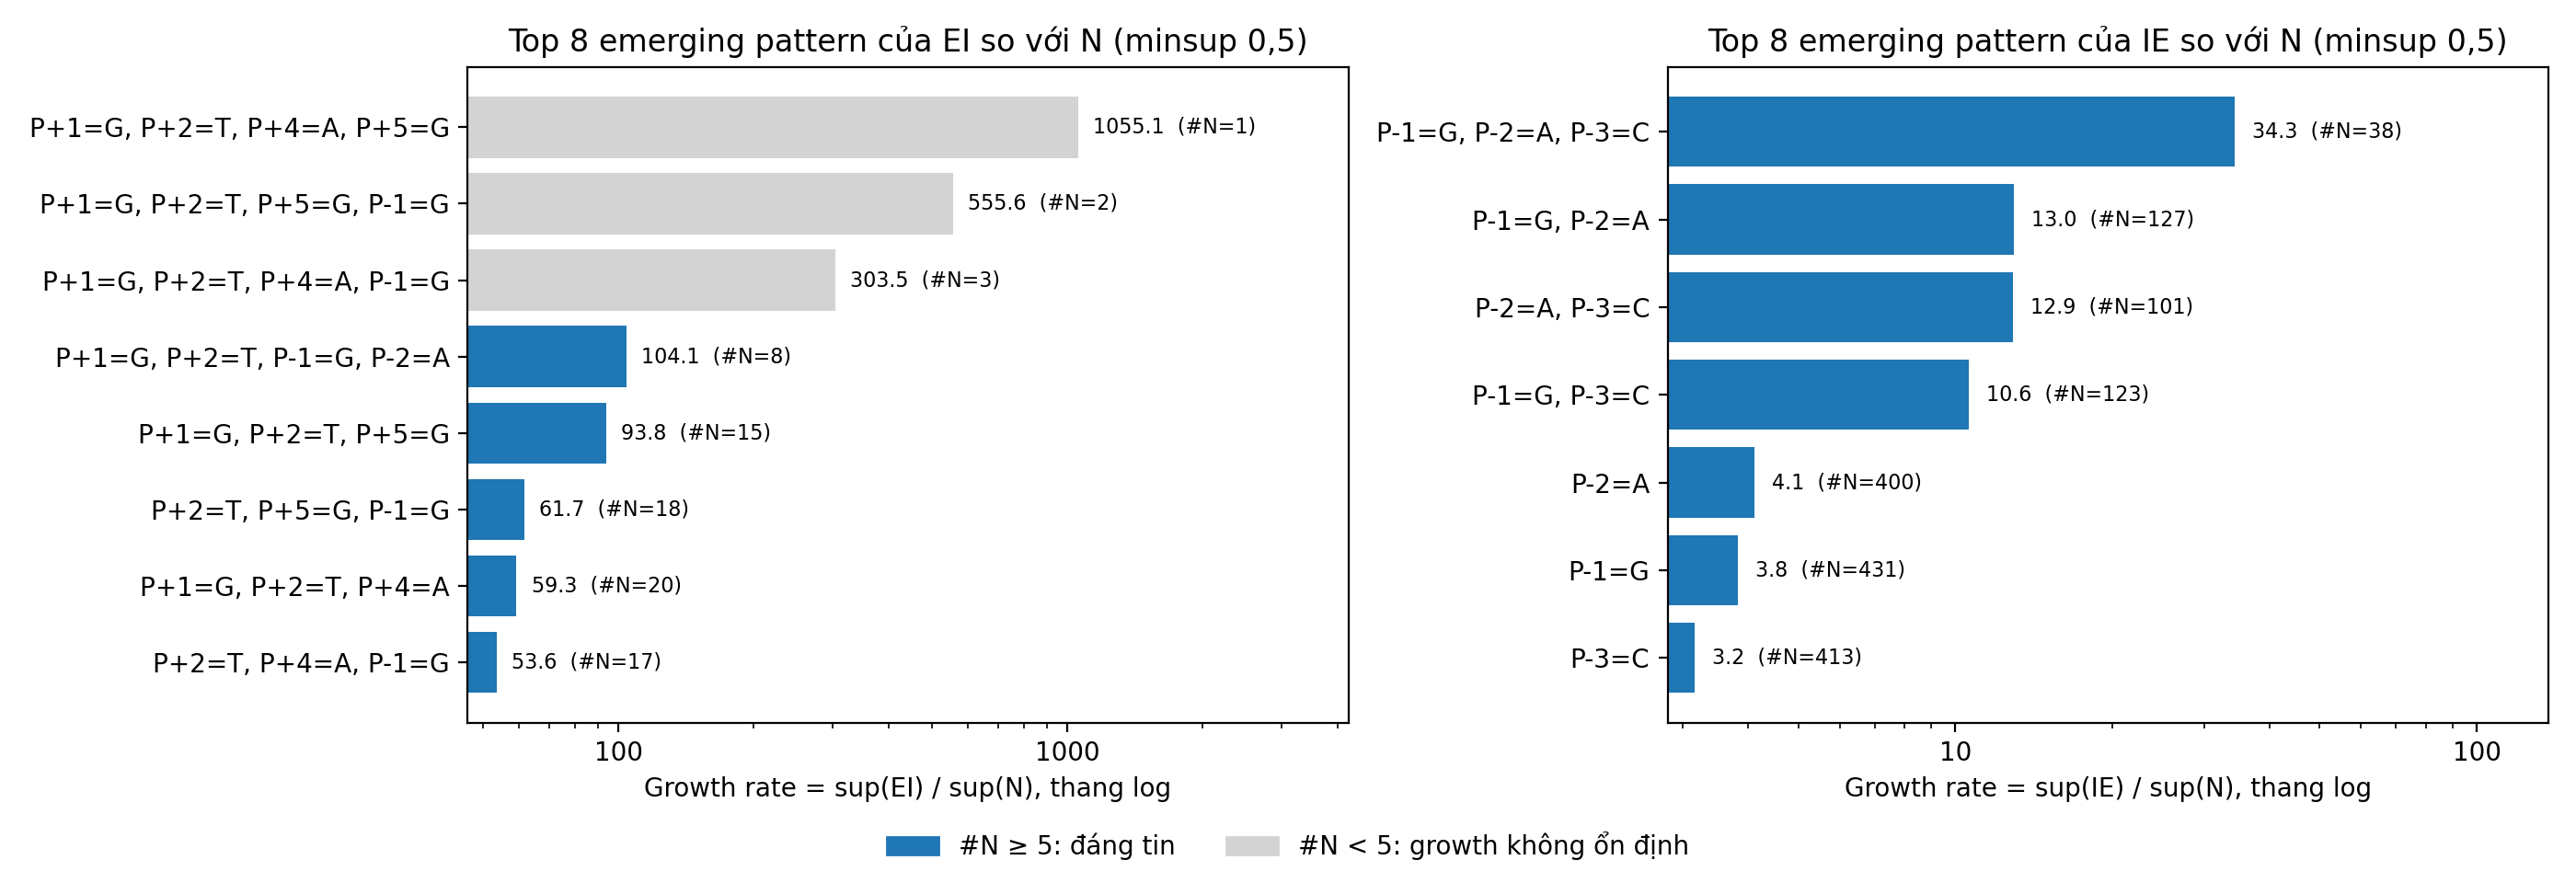

In [45]:
from scripts.app2_plot import plot_emerging

plot_emerging(groups, code)
display(Image("docs/figures/app2_emerging.png", width=900))

**Nhận xét.**

- **Chỉ GT hay AG là chưa đủ để nhận ra ranh giới.** `{P+1=G, P+2=T}` vẫn xuất hiện trong
  **5,9%** mẫu N, xấp xỉ 1/16 = 6,25%, đúng xác suất để hai vị trí bất kỳ ngẫu nhiên là "G
  rồi T". Tương tự `AG` có trong 7,7% mẫu N. Một gen dài hàng chục nghìn nucleotide chứa
  hàng nghìn cặp GT và AG, nhưng chỉ vài cặp là ranh giới thật. Vì vậy tế bào phải dựa vào
  **các vị trí lân cận**: thêm `P+5=G` thì N tụt từ 5,9% xuống **0,9%** và growth tăng từ
  16,7 lên **93,8**. FP-Growth tìm ra đúng hiện tượng sinh học này: tín hiệu splice là một
  *tổ hợp* nhiều vị trí, không phải một cặp chữ.
- **Pattern đáng tin nhất của donor** theo hiệu support (khi `#N ≥ 5`) là
  `{P+1=G, P+2=T, P+5=G}`: có ở 85,0% mẫu EI và chỉ 0,9% mẫu N, phân biệt được **84,1%**
  số mẫu. Các pattern growth hàng trăm ở bảng đầu đều dựa trên 1–3 mẫu N nên chỉ nên xem là
  gợi ý.
- **Acceptor có growth thấp hơn hẳn**: cao nhất chỉ 34,3 (`{P-3=C, P-2=A, P-1=G}`), so với
  104,1 ở donor (`{P-2=A, P-1=G, P+1=G, P+2=T}`, cùng điều kiện `#N ≥ 5`). Không phải vì acceptor có tín hiệu yếu hơn, mà vì
  cách mã hoá hiện tại **không thấy** một nửa tín hiệu của acceptor. Mục 4.7 giải thích lý
  do.

### 4.7. Hạn chế: polypyrimidine tract bị "tàng hình"

Ở 4.4, consensus IE có 14 vị trí `Y` liên tiếp, nhưng không itemset nào của IE ở minsup
0,5 chứa vị trí nào trước −3. Xem kỹ vùng −15 … −5:

In [46]:
vung = bang_tan_suat(seqs["IE"], 15, 26)      # vị trí -15 .. -5
vung["max(C, T)"] = vung[["C", "T"]].max(axis=1)
vung["C + T"] = vung["C"] + vung["T"]
display(vung[["C", "T", "max(C, T)", "C + T"]].T)

vị trí,-15,-14,-13,-12,-11,-10,-9,-8,-7,-6,-5
C,0.38,0.35,0.35,0.37,0.36,0.37,0.36,0.42,0.45,0.46,0.40
T,0.39,0.42,0.44,0.44,0.46,0.45,0.43,0.41,0.39,0.43,0.46
"max(C, T)",0.39,0.42,0.44,0.44,0.46,0.45,0.43,0.42,0.45,0.46,0.46
C + T,0.77,0.77,0.79,0.81,0.82,0.82,0.79,0.83,0.84,0.89,0.86


In [47]:
# Mỗi mẫu có bao nhiêu vị trí là pyrimidine (C hoặc T) trong vùng -15..-5 (11 vị trí)?
def so_pyrimidine(s):
    return sum(1 for i in range(15, 26) if s[i] in "CT")

for label in ["IE", "N"]:
    dem = [so_pyrimidine(s) for s in seqs[label]]
    ty_le_8 = sum(1 for d in dem if d >= 8) / len(dem)
    print(f"{label:>2}: trung bình {sum(dem) / len(dem):.1f}/11 vị trí là C/T | "
          f"có ≥ 8/11: {ty_le_8:.1%} số mẫu")

IE: trung bình 9.0/11 vị trí là C/T | có ≥ 8/11: 86.7% số mẫu
 N: trung bình 5.4/11 vị trí là C/T | có ≥ 8/11: 16.5% số mẫu


**Nhận xét.**

- Ở mọi vị trí từ −15 đến −5, **C hoặc T cộng lại chiếm 77–89%**, nhưng **từng chữ riêng
  lẻ chỉ 35–46%**, đều dưới minsup 0,5. Tín hiệu bị *chia đôi* giữa hai item `P-k=C` và
  `P-k=T`, nên không item nào đủ support để vào FP-tree.
- Tín hiệu này lại rất mạnh: trung bình một mẫu IE có **9,0/11** vị trí là pyrimidine, so
  với **5,4/11** của N; **86,7%** mẫu IE có ít nhất 8/11 vị trí là C/T, trong khi N chỉ
  16,5%.
- **Nguyên nhân sinh học:** protein nhận diện vùng này (U2AF) bám vào "một dải C/T" chứ
  không cần đúng chữ C hay đúng chữ T ở từng vị trí. Tín hiệu nằm ở **lớp** nucleotide
  (pyrimidine), không nằm ở từng nucleotide cụ thể. Vị trí +3 của donor (R = A hoặc G) cũng
  bị bỏ sót vì cùng lý do.
- **Bài học về cách biến đổi dữ liệu:** FP-Growth chỉ tìm được những gì cách mã hoá cho
  phép nó thấy. Chọn item là bước quyết định, không kém gì chọn minsup.

### 4.8. Mở rộng: thêm item lớp nucleotide (Y/R)

**Ý tưởng:** trong vùng −20 … −4, thay item `P-k=C` / `P-k=T` bằng **`P-k=Y`**, và
`P-k=A` / `P-k=G` bằng **`P-k=R`**. Ngoài vùng này giữ nguyên nucleotide.

Vì sao chỉ *thay* chứ không *thêm*? Nếu giữ cả `P-1=G` lẫn `P-1=R` thì hai item luôn đi cùng
nhau (G là một R). Số itemset sẽ bùng nổ (thử nghiệm: IE ở minsup 0,3 lên khoảng 833 nghìn
itemset) mà phần lớn là bản sao vô nghĩa của nhau. Thay hẳn trong một vùng cố định thì
mỗi vị trí vẫn chỉ có một item.

In [48]:
from src.utils import encode

LOP = {"A": "R", "G": "R", "C": "Y", "T": "Y"}

def to_transaction_yr(seq, tu=-20, den=-4):
    """Như to_transaction, nhưng vị trí trong [tu, den] dùng lớp Y/R thay cho nucleotide."""
    items = []
    for i, base in enumerate(seq):
        if base not in "ACGT":
            continue
        pos = position_name(i)
        if tu <= int(pos) <= den:
            items.append(f"P{pos}={LOP[base]}")
        else:
            items.append(f"P{pos}={base}")
    return items

nhan = [l for l, _ in rows]
encoded_yr, code_yr = encode([to_transaction_yr(s) for _, s in rows])   # bảng mã chung
groups_yr = {"EI": [], "IE": [], "N": []}
for l, t in zip(nhan, encoded_yr):
    groups_yr[l].append(t)
name_yr = invert_code(code_yr)

for label, data in groups_yr.items():
    kq = fpgrowth(data, to_min_count(0.5, len(data)))
    dai_nhat = max((len(k) for k in kq), default=0)
    print(f"{label:>2}: {len(kq):5d} itemset ở minsup 0,5, dài nhất {dai_nhat} item")

EI:    97 itemset ở minsup 0,5, dài nhất 4 item
IE:  1850 itemset ở minsup 0,5, dài nhất 6 item
 N:    16 itemset ở minsup 0,5, dài nhất 1 item


In [49]:
# Itemset dài nhất của IE
kq_ie = decode(fpgrowth(groups_yr["IE"], to_min_count(0.5, len(groups_yr["IE"]))), code_yr)
dai = sorted(kq_ie.items(), key=lambda x: (-len(x[0]), -x[1]))[:3]
for itemset, sup in dai:
    print(f"{sup / len(groups_yr['IE']):6.1%}  {sorted(itemset)}")

 56.9%  ['P-1=G', 'P-2=A', 'P-5=Y', 'P-6=Y', 'P-7=Y', 'P-8=Y']
 56.5%  ['P-11=Y', 'P-1=G', 'P-2=A', 'P-5=Y', 'P-6=Y', 'P-7=Y']
 56.1%  ['P-10=Y', 'P-1=G', 'P-2=A', 'P-5=Y', 'P-6=Y', 'P-7=Y']


In [50]:
# Emerging pattern của IE với cách mã hoá mới (#N >= 5, xếp theo growth)
rows_yr = emerging(groups_yr["IE"], groups_yr["N"], 0.5)
rows_yr = [r for r in rows_yr if r[4] >= MIN_N]
rows_yr.sort(key=lambda r: r[3], reverse=True)
pd.DataFrame([{"itemset": ", ".join(sorted(name_yr[i] for i in r[0])),
               "IE": f"{r[1]:.1%}", "N": f"{r[2]:.1%}", "#N": r[4],
               "growth": round(r[3], 1)} for r in rows_yr[:6]])

,itemset,IE,N,#N,growth
0,"P-12=Y, P-1=G, P-2=A, P-5=Y, P-6=Y, P-7=Y",55.7%,0.3%,5,184.5
1,"P-10=Y, P-11=Y, P-1=G, P-2=A, P-5=Y, P-6=Y",55.5%,0.3%,5,183.6
2,"P-10=Y, P-1=G, P-2=A, P-5=Y, P-6=Y, P-8=Y",54.8%,0.3%,5,181.4
3,"P-11=Y, P-12=Y, P-1=G, P-2=A, P-5=Y, P-6=Y",54.6%,0.3%,5,180.6
4,"P-12=Y, P-1=G, P-2=A, P-6=Y, P-7=Y, P-8=Y",53.9%,0.3%,5,178.4
5,"P-11=Y, P-12=Y, P-1=G, P-2=A, P-6=Y, P-8=Y",53.0%,0.3%,5,175.4


**Nhận xét.**

- Với item lớp Y/R, FP-Growth **thấy được polypyrimidine tract**: itemset dài nhất của IE
  là `{P-8=Y, P-7=Y, P-6=Y, P-5=Y, P-2=A, P-1=G}` (56,9% mẫu), tức một dải pyrimidine đi
  liền với `AG`, đúng cấu trúc `(Y)n …AG|` của acceptor.
- **Growth tốt nhất của IE tăng từ 34,3 lên khoảng 184** (vẫn giữ điều kiện `#N ≥ 5`),
  cao hơn cả donor (104,1). Điều này xác nhận nhận định ở 4.6: acceptor không có tín hiệu
  yếu hơn, chỉ là cách mã hoá cũ không nhìn thấy nó. Lưu ý các pattern đầu bảng đều có
  `#N = 5`, vừa chạm ngưỡng lọc, nên con số 184 là ước lượng thô; điều chắc chắn là growth
  tăng **nhiều lần** so với 34,3.
- **Lưu ý mức nền mới:** item lớp có 2 khả năng thay vì 4, nên mức nền là **50%** chứ không
  phải 25%. Vì thế ở minsup 0,5 nhóm N đã có **16 itemset** (đều chỉ 1 item), chỉ là "vượt
  nền do may". Khi đổi cách mã hoá thì **không được so số itemset với mục 4.3**; phải so với
  nhóm đối chứng N qua growth rate, đúng như đã làm ở ô trên.
- **Giới hạn của mở rộng này:** vùng −20 … −4 được chọn *sau khi* đã nhìn heatmap ở 4.4,
  tức có dùng hiểu biết từ dữ liệu. Một cách tổng quát hơn là cho FP-Growth chạy trên cả
  item nucleotide lẫn item lớp ở mọi vị trí, rồi lọc bỏ các itemset thừa (closed itemset).
  Đó là hướng phát triển tiếp theo.

### 4.9. Kết luận

**FP-Growth của nhóm, không được cho trước kiến thức sinh học nào, đã tìm lại được:**

1. **Quy tắc GT–AG**: `{P+1=G, P+2=T}` có trong 99,0% donor, `{P-2=A, P-1=G}` có trong
   99,5% acceptor.
2. **Consensus đầy đủ của donor `MAG|GTRAGT`**, khớp với sách sinh học phân tử.
3. **Tỉ lệ intron GC–AG** (0,52%) khớp với số liệu công bố của Burset và cộng sự (0,56%),
   và phát hiện một số mẫu có ranh giới chú thích lệch.
4. **Tín hiệu splice là tổ hợp nhiều vị trí**: GT đơn lẻ vẫn gặp trong 5,9% đoạn DNA
   ngẫu nhiên, thêm `P+5=G` thì chỉ còn 0,9%, growth tăng từ 16,7 lên 93,8.
5. **Polypyrimidine tract** của acceptor, nhưng chỉ khi đổi sang item lớp Y/R (4.8). Với
   cách mã hoá thông thường thì tín hiệu này bị chia đôi giữa C và T và không vượt minsup.

**Ứng dụng của các pattern:** các itemset có growth cao có thể dùng trực tiếp làm **đặc
trưng** (*feature*) cho một bộ phân loại nhận diện splice site, hoặc làm **luật** kiểu
"nếu chuỗi chứa `{P+1=G, P+2=T, P+5=G}` thì nhiều khả năng là donor". Đây cũng chính là
cách các chương trình dự đoán gen dùng *weight matrix* dựng từ consensus.

**Hạn chế:**

- Dữ liệu chỉ có 60 nucleotide quanh ranh giới, nên không thấy được tín hiệu xa hơn như
  *branch point* (thường cách acceptor 20–50 nucleotide).
- Growth rate không ổn định khi pattern hiếm trong N; nhóm chỉ lọc theo `#N ≥ 5`, chưa
  kiểm định thống kê.
- Vùng dùng item Y/R ở 4.8 được chọn bằng tay sau khi xem dữ liệu.

**Tái lập:** toàn bộ mục 4 không có ngẫu nhiên; chạy ngoài notebook bằng
`python -m scripts.app2_explore`, `app2_check`, `app2_emerging`, `app2_plot`.

#### Tài liệu tham khảo (Ứng dụng 2)

1. G. Towell, M. Noordewier, J. Shavlik. *Molecular Biology (Splice-junction Gene
   Sequences).* UCI Machine Learning Repository, 1992.
2. M. Burset, I. A. Seledtsov, V. V. Solovyev. *Analysis of canonical and non-canonical
   mammalian splice sites.* Nucleic Acids Research, 28(21):4364–4375, 2000.
3. G. Dong, J. Li. *Efficient Mining of Emerging Patterns: Discovering Trends and
   Differences.* Proc. KDD'99, 1999.